# ML2 baseline: hourly power per turbine from forecast-available inputs (CARE)

**Role in the pipeline.** When two or more turbines of the same park have failure days close together, the dispatch agent
asks ML2 for each turbine's expected production over the next 7 days and repairs the higher producer first. What matters is
therefore the **7-day energy per turbine** and the **order between turbines of the same park**, not 10-minute accuracy.

**Serving constraint.** At inference the only input is the Open-Meteo forecast in `park_wind_forecast` (hourly, 7 days,
one row per park and hour): `wind_speed_10m`, `wind_speed_100m`, `wind_direction_10m/100m`, `wind_gusts_10m`,
`temperature_2m` (Celsius), `relative_humidity_2m`, `dew_point_2m`, `surface_pressure`. The main model may only use
features that can be computed from those columns. Rotor speed, pitch, internal temperatures, reactive power and any lag of
power are not available seven days ahead; they appear only in one diagnostic model that is marked as not deployable.

**Data.** CARE wind-turbine SCADA (`dataset/wind_turbine_scada_fault/raw`, comma variant only), farms A, B and C. The
conventions of the ML1 baseline (`notebooks/care_catboost_baseline.md`) are kept: the time axis is `time_stamp`, a timeline
is one turbine with only identical overlaps merged, exact zeros in temperatures are dropped readings, and
`status_type_id` is never a feature (in Farm A it follows the fault log).

Contents:
1. Load and check the known facts
2. Timelines and time-aligned groups of turbines
3. Target: available production (cleaning rules), availability per turbine
4. Hourly table and the bias of averaging wind before the power curve
5. Features and the serving contract
6. Validation schemes
7. Models and baselines
8. Results: hourly, 7-day energy, ordering of turbines
9. Forecast-error sensitivity
10. Ablations
11. Final models, feature contract, 7-day predictions
12. Summary

In [1]:
import io
import json
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
from catboost import CatBoostRegressor
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image as PILImage
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "wind_turbine_scada_fault" / "raw"
CACHE = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache"
OUT = CACHE / "ml2_baseline"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models" / "ml2"
MODELS.mkdir(parents=True, exist_ok=True)
FOLDS_PATH = CACHE / "catboost_baseline" / "cv_folds.parquet"   # the ML1 folds, reused

FAST = False   # debugging only: subsample rows and use few trees

FARMS = ["A", "B", "C"]
# 10-minute columns per farm. ws = nacelle wind speed, p = active power (capacity factor), amb = ambient temperature,
# wdir = absolute wind direction (A and B only), p_avail = the turbine's own "possible / available power" (A and B only,
# used only to validate the curtailment rule). rotor and pitch feed only the diagnostic model.
COLS = {
    "A": dict(ws="wind_speed_3_avg", ws_max="wind_speed_3_max", ws_std="wind_speed_3_std", p="power_30_avg",
              amb="sensor_0_avg", wdir="sensor_1_avg", rotor="sensor_52_avg", pitch="sensor_5_avg", p_avail="power_29_avg"),
    "B": dict(ws="wind_speed_61_avg", ws_max="wind_speed_61_max", ws_std="wind_speed_61_std", p="power_62_avg",
              amb="sensor_8_avg", wdir="sensor_4_avg", rotor="sensor_25_avg", pitch="sensor_10_avg", p_avail="power_58_avg"),
    "C": dict(ws="wind_speed_236_avg", ws_max="wind_speed_236_max", ws_std="wind_speed_236_std", p="power_6_avg",
              amb="sensor_7_avg", wdir=None, rotor="sensor_144_avg", pitch="sensor_103_avg", p_avail=None),
}
VARS = ["ws", "ws_max", "ws_std", "p", "amb", "wdir", "rotor", "pitch", "p_avail"]

CUT_IN, RATED, CUT_OUT = 3.0, 13.0, 25.0   # theoretical curve, as in smarthack/wind/constants.py
REPAIR_DAYS = 14                           # removed after every anomaly window, as in ML1
OPER_LO, OPER_HI = 4.5, 20.0               # wind range (m/s) in which a healthy, unconstrained turbine must produce
STOP_P = 0.01                              # power at or below this inside the range = stopped
ENV_Q, CURT_FRAC, CURT_ABS = 0.90, 0.70, 0.05   # curtailed = power < 0.70 x envelope(ws) - 0.05 (section 3)
BIN = 0.5                                  # wind-speed bin width (m/s) for curves
MIN_ROWS_HOUR = 4                          # of 6 ten-minute rows: fewer clean rows and the hour has no target
WEEK_MIN_HOURS = 120                       # of 168: fewer clean hours and the 7-day window is not scored
FUTURE_FRAC = 0.80                         # future scheme: first 80% of every timeline's time span trains
SEED = 0
N_BOOT = 1000
CB_PARAMS = dict(depth=6, iterations=600, learning_rate=0.05, l2_leaf_reg=10, loss_function="RMSE",
                 thread_count=-1, verbose=False, allow_writing_files=False, random_seed=SEED)
INNER_MAX_ROWS = 150_000                   # rows per inner early-stopping fit
# Forecast error of hub-height wind speed by lead time (m/s, standard deviation) used for the sensitivity test. These are
# assumed typical values for NWP 100 m wind, NOT measured on our parks; see section 9.
NOISE_SD = {"day 1": 1.5, "day 3": 2.2, "day 7": 3.3}
NOISE_RHO = 0.95                           # hour-to-hour autocorrelation of the forecast error
N_NOISE = 3
if FAST:
    CB_PARAMS["iterations"] = 120
    N_BOOT = 200
    INNER_MAX_ROWS = 40_000

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c2"
BLUE, ORANGE, AQUA, RED, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#c0392b", "#7d5ba6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})


def show(fig, name, dpi=80, colors=96):
    """Save the full-resolution PNG to the cache and show a small palette PNG inline (repo limit 500 KB per file)."""
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    img = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(IPImage(out.getvalue()))


T0 = time.time()
print("root:", ROOT)

root: /Users/alexandrucojoaca/Documents/Smarthack


## 1. Load and check the known facts

Only the columns listed above are read, from every `comma_*.csv`. Exact zeros in ambient temperature become missing
(dropped readings), negative wind speeds become missing.

In [2]:
def dataset_paths(farm):
    return sorted((RAW / f"Wind Farm {farm}" / "datasets").glob("comma_*.csv"), key=lambda p: int(p.stem.split("_")[1]))


def read_dataset(job):
    farm, path = job
    m = {k: v for k, v in COLS[farm].items() if v}
    t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(
        include_columns=["time_stamp", "asset_id", "id", "train_test", "status_type_id"] + list(m.values())))
    d = pd.DataFrame({"time_stamp": t["time_stamp"].to_numpy().astype("datetime64[s]"),
                      "asset_id": t["asset_id"].to_numpy(), "id": t["id"].to_numpy(),
                      "status": t["status_type_id"].to_numpy()})
    for k in VARS:
        d[k] = t[m[k]].to_numpy(zero_copy_only=False).astype(np.float32) if k in m else np.float32(np.nan)
    d["farm"] = farm
    d["event_id"] = int(path.stem.split("_")[1])
    return d


with ThreadPoolExecutor(max_workers=6) as ex:
    D = pd.concat(list(ex.map(read_dataset, [(f, p) for f in FARMS for p in dataset_paths(f)])), ignore_index=True)
D["turbine"] = D["farm"] + D["asset_id"].map("{:02d}".format)
D.loc[D["amb"] == 0, "amb"] = np.nan
D.loc[D["ws"] < 0, "ws"] = np.nan

EVENTS_RAW = pd.concat([pd.read_csv(RAW / f"Wind Farm {f}" / "comma_event_info.csv", encoding="latin-1").assign(farm=f)
                        for f in FARMS], ignore_index=True)

facts = []
for f, g in D.groupby("farm"):
    facts.append({"farm": f, "datasets": g["event_id"].nunique(), "turbines": g["turbine"].nunique(),
                  "10-min rows": len(g), "power p99": round(float(g["p"].quantile(0.99)), 3),
                  "power max": round(float(g["p"].max()), 3), "rows with power < 0 (%)": round(100 * float((g["p"] < 0).mean()), 1),
                  "ambient median (C)": round(float(g["amb"].median()), 1),
                  "ambient p05..p95 (C)": f"{g['amb'].quantile(0.05):.1f}..{g['amb'].quantile(0.95):.1f}",
                  "absolute wind direction": COLS[f]["wdir"] or "none",
                  "available-power column": COLS[f]["p_avail"] or "none",
                  "wind p50 / p99 (m/s)": f"{g['ws'].median():.1f} / {g['ws'].quantile(0.99):.1f}"})
display(pd.DataFrame(facts).set_index("farm").T)
print(f"loaded {len(D):,} rows in {time.time() - T0:.0f} s")

farm                                A             B           C
datasets                           22            15          58
turbines                            5             9          22
10-min rows                   1196747        859065     3187136
power p99                       0.976         1.029       1.012
power max                       0.976         1.031       1.071
rows with power < 0 (%)          29.3          19.4        16.3
ambient median (C)               19.0          12.6        28.1
ambient p05..p95 (C)       12.0..30.0     5.2..20.8  20.0..36.3
absolute wind direction  sensor_1_avg  sensor_4_avg        none
available-power column   power_29_avg  power_58_avg        none
wind p50 / p99 (m/s)       5.5 / 16.9    8.1 / 21.2  6.9 / 20.3

loaded 5,242,948 rows in 9 s


Checked here: power is a capacity factor (p99 about 1.0 in every farm) and a sizeable share of rows is slightly negative
(consumption while idle). Farm C's ambient temperature is shifted (median about 28 C), so it is centred per farm before
use (section 5). Absolute wind direction exists only in A and B.

## 2. Timelines and time-aligned groups of turbines

**Timelines (same rule as ML1).** Datasets of the same turbine are merged only when their overlapping rows are identical;
12 of the 22 overlapping same-turbine pairs carry different data on the same anonymised timestamps.

**Time-aligned groups (new here).** The ordering metric needs turbines of the same park observed over the *same real
week*. Timestamps are anonymised per dataset, so a shared timestamp does not by itself mean a shared real time. Two
datasets of different turbines are put in the same time group when their hourly wind speeds correlate above 0.8 over at
least 3 shared days: turbines of one park see the same weather, unrelated periods do not.

In [3]:
def find_timelines(D):
    seg, pairs = {}, []
    for f in FARMS:
        d = D[D["farm"] == f]
        meta = d.groupby("event_id").agg(asset_id=("asset_id", "first"), start=("time_stamp", "min"))
        frames = {e: g.set_index("time_stamp")[["ws", "p", "amb"]] for e, g in d.groupby("event_id")}
        parent = {e: e for e in meta.index}

        def root(e):
            while parent[e] != e:
                e = parent[e]
            return e

        for a, g in meta.groupby("asset_id"):
            for i, j in combinations(g.sort_values("start").index, 2):
                x, y = frames[i], frames[j]
                common = x.index.intersection(y.index)
                if len(common) == 0:
                    continue
                X, Y = x.loc[common].to_numpy(), y.loc[common].to_numpy()
                same = float(((np.abs(X - Y) < 1e-6) | (np.isnan(X) & np.isnan(Y))).all(axis=1).mean())
                pairs.append(dict(farm=f, asset_id=a, dataset_1=i, dataset_2=j, overlap_days=round(len(common) / 144, 1),
                                  identical_share=round(same, 4)))
                if same > 0.99:
                    parent[root(i)] = root(j)
        comp = {e: root(e) for e in meta.index}
        for a, g in meta.groupby("asset_id"):
            roots = sorted({comp[e] for e in g.index}, key=lambda r: g.loc[[e for e in g.index if comp[e] == r], "start"].min())
            for k, r in enumerate(roots):
                for e in g.index:
                    if comp[e] == r:
                        seg[e] = f"{f}{a:02d}-{k}"
    return seg, pd.DataFrame(pairs)


SEG, PAIRS_OVERLAP = find_timelines(D)
D["segment"] = D["event_id"].map(SEG)
n_before = len(D)
D = D.sort_values(["segment", "time_stamp", "event_id"]).drop_duplicates(["segment", "time_stamp"]).reset_index(drop=True)
print(f"identical overlap rows removed: {n_before - len(D):,}")
ov = PAIRS_OVERLAP.assign(identical=PAIRS_OVERLAP["identical_share"] > 0.99).groupby("farm")["identical"].agg(["size", "sum"])
ov.columns = ["overlapping same-turbine pairs", "identical (merged)"]
ov["timelines"] = D.groupby("farm")["segment"].nunique()
display(ov)

identical overlap rows removed: 406,292


      overlapping same-turbine pairs  identical (merged)  timelines
farm                                                               
A                                  8                   5         17
B                                  1                   1         14
C                                 13                   4         54

In [4]:
def find_time_groups(D):
    hourly = D.assign(hour=D["time_stamp"].dt.floor("h")).groupby(["farm", "segment", "hour"])["ws"].mean()
    group, links = {}, []
    for f in FARMS:
        piv = hourly.loc[f].unstack("segment")
        segs = list(piv.columns)
        turb = {s: s.split("-")[0] for s in segs}
        parent = {s: s for s in segs}

        def root(s):
            while parent[s] != s:
                s = parent[s]
            return s

        valid = piv.notna().to_numpy()
        vals = piv.to_numpy()
        for a, b in combinations(range(len(segs)), 2):
            m = valid[:, a] & valid[:, b]
            if m.sum() < 72:
                continue
            c = float(np.corrcoef(vals[m, a], vals[m, b])[0, 1])
            links.append(dict(farm=f, segment_1=segs[a], segment_2=segs[b], same_turbine=turb[segs[a]] == turb[segs[b]],
                              shared_days=round(m.sum() / 24, 1), corr=round(c, 3)))
            if c > 0.8:
                parent[root(segs[a])] = root(segs[b])
        roots = sorted({root(s) for s in segs})
        for k, r in enumerate(roots):
            for s in segs:
                if root(s) == r:
                    group[s] = f"{f}g{k:02d}"
    links = pd.DataFrame(links)
    links["same_group"] = [group[a] == group[b] for a, b in zip(links["segment_1"], links["segment_2"])]
    return group, links


GROUP, LINKS = find_time_groups(D)
D["group"] = D["segment"].map(GROUP)
bad = LINKS[LINKS["same_turbine"] & LINKS["same_group"]]
assert bad.empty, "the same turbine shows different data at the same real time"
print("hourly wind correlation of overlapping timelines (different turbines): share in (0.5, 0.8):",
      round(float(((LINKS["corr"] > 0.5) & (LINKS["corr"] < 0.8) & ~LINKS["same_turbine"]).mean()), 3))
gs = D.groupby(["farm", "group"]).agg(timelines=("segment", "nunique"), turbines=("turbine", "nunique"))
gt = gs.groupby("farm").agg(groups=("turbines", "size"), groups_with_2plus_turbines=("turbines", lambda s: int((s >= 2).sum())),
                            largest_group_turbines=("turbines", "max"))
display(gt)

hourly wind correlation of overlapping timelines (different turbines): share in (0.5, 0.8): 0.0


      groups  groups_with_2plus_turbines  largest_group_turbines
farm                                                            
A          7                           5                       4
B          8                           5                       3
C         15                          15                       7

The correlations split cleanly: overlapping timelines of different turbines either track each other (r > 0.8) or not at
all, with nothing in between. Within a time group the anonymised timestamps therefore mark the same real hour for every
turbine, which is what the pairwise ordering test in section 8 needs. No turbine appears with different data inside one
group.

## 3. Target: available production

The target is the production of a **healthy turbine in operation, not held back**. Removed, in this order:
1. **Anomaly windows** (`event_start` .. `event_end`, located by `event_start_id` / `event_end_id`) and the **14 days of
   repair** after each window. Windows of normal datasets are reference periods and stay.
2. **Stops**: wind between 4.5 and 20 m/s but power at or below 0.01.
3. **Curtailment / derating**: wind between 4.5 and 20 m/s and power below `0.70 x envelope(ws) - 0.05`, where the
   envelope is the farm's 90th percentile of producing rows per 0.5 m/s wind bin (made monotone). The margin was chosen
   so the rule is conservative; it is validated below against the turbines' own available-power signal in A and B.

Rows below 4.5 m/s (start-up, small negative consumption) and at or above 20 m/s (storm control) are kept as they are:
there the low output is physics, not a fault. `status_type_id` is not used for the target; it is only compared.

In [5]:
def event_windows():
    """Anomaly windows located by event_start_id / event_end_id in each dataset's own rows (never by timestamp)."""
    rows = []
    for _, r in EVENTS_RAW[EVENTS_RAW["event_label"] == "anomaly"].iterrows():
        raw = read_ids(r["farm"], r["event_id"])
        s = raw.loc[raw["id"] == r["event_start_id"], "time_stamp"].iloc[0]
        e = raw.loc[raw["id"] == r["event_end_id"], "time_stamp"].iloc[0]
        rows.append(dict(farm=r["farm"], event_id=r["event_id"], segment=SEG[r["event_id"]], start=s, end=e))
    return pd.DataFrame(rows)


def read_ids(farm, event_id):
    t = pacsv.read_csv(RAW / f"Wind Farm {farm}" / "datasets" / f"comma_{event_id}.csv",
                       convert_options=pacsv.ConvertOptions(include_columns=["time_stamp", "id"]))
    return pd.DataFrame({"time_stamp": t["time_stamp"].to_numpy().astype("datetime64[s]"), "id": t["id"].to_numpy()})


EV = event_windows()
ts = D["time_stamp"].to_numpy()
seg_arr = D["segment"].to_numpy()
D["window"] = False
D["repair"] = False
seg_index = {s: np.flatnonzero(seg_arr == s) for s in D["segment"].unique()}
win, rep = np.zeros(len(D), bool), np.zeros(len(D), bool)
for _, r in EV.iterrows():
    idx = seg_index[r["segment"]]
    t = ts[idx]
    win[idx[(t >= np.datetime64(r["start"])) & (t <= np.datetime64(r["end"]))]] = True
    rep[idx[(t > np.datetime64(r["end"])) & (t <= np.datetime64(r["end"]) + np.timedelta64(REPAIR_DAYS, "D"))]] = True
D["window"], D["repair"] = win, rep & ~win
D["event_excl"] = D["window"] | D["repair"]
D["valid"] = D["ws"].notna() & D["p"].notna()
D["bin"] = np.floor(D["ws"].fillna(-1) / BIN).astype(int)
NBINS = int(40 / BIN)


def binned(ws_bin, values, stat, min_n=20):
    """Per wind bin statistic, interpolated over empty bins, indexed 0..NBINS-1."""
    s = pd.Series(values).groupby(np.asarray(ws_bin))
    s = s.quantile(stat) if isinstance(stat, float) else s.agg(stat)
    cnt = pd.Series(values).groupby(np.asarray(ws_bin)).size()
    s = s[cnt >= min_n]
    s = s[(s.index >= 0) & (s.index < NBINS)]
    return s.reindex(range(NBINS)).interpolate(limit_direction="both")


ENVELOPE, REF10 = {}, {}
for f in FARMS:
    m = (D["farm"] == f) & D["valid"] & ~D["event_excl"] & (D["p"] > STOP_P)
    ENVELOPE[f] = binned(D.loc[m, "bin"], D.loc[m, "p"].to_numpy(), ENV_Q).cummax()
fm = D["farm"].to_numpy()
env = np.full(len(D), np.nan)
for f in FARMS:
    i = fm == f
    env[i] = ENVELOPE[f].to_numpy()[np.clip(D["bin"].to_numpy()[i], 0, NBINS - 1)]
D["envelope"] = env
in_range = D["valid"] & (D["ws"] >= OPER_LO) & (D["ws"] < OPER_HI)
D["stop"] = in_range & (D["p"] <= STOP_P)
D["curtail"] = in_range & ~D["stop"] & (D["p"] < CURT_FRAC * D["envelope"] - CURT_ABS)
D["clean"] = D["valid"] & ~D["event_excl"] & ~D["stop"] & ~D["curtail"]
# empirical 10-minute available curve per farm (median of clean rows), used for availability and the averaging bias
for f in FARMS:
    m = (D["farm"] == f) & D["clean"]
    REF10[f] = binned(D.loc[m, "bin"], D.loc[m, "p"].to_numpy(), "median")
ref = np.full(len(D), np.nan)
for f in FARMS:
    i = fm == f
    ref[i] = REF10[f].to_numpy()[np.clip(D["bin"].to_numpy()[i], 0, NBINS - 1)]
D.loc[D["ws"].isna(), "bin"] = -1
D["ref10"] = np.where(D["ws"].notna(), ref, np.nan)

cut = []
for f, g in D.groupby("farm"):
    out = ~g["event_excl"]
    hi = g["valid"] & out & (g["ws"] >= 13) & (g["ws"] < OPER_HI)
    cut.append({"farm": f, "rows": len(g), "missing wind or power %": 100 * (~g["valid"]).mean(),
                "anomaly window %": 100 * g["window"].mean(), "repair 14 d %": 100 * g["repair"].mean(),
                "stop %": 100 * (g["stop"] & out).mean(), "curtailed %": 100 * (g["curtail"] & out).mean(),
                "clean %": 100 * g["clean"].mean(),
                "curtailed % of rows at 13-20 m/s": 100 * g.loc[hi, "curtail"].mean(),
                "stopped % of rows at 13-20 m/s": 100 * g.loc[hi, "stop"].mean()})
CUT = pd.DataFrame(cut).set_index("farm").round(2)
display(CUT)

         rows  missing wind or power %  anomaly window %  repair 14 d %  stop %  curtailed %  clean %  curtailed % of rows at 13-20 m/s  stopped % of rows at 13-20 m/s
farm                                                                                                                                                                   
A     1014782                     0.00              1.63           0.67    1.96         0.17    95.57                              0.69                            9.59
B      806909                     0.00              4.21           0.57    6.78        12.19    76.24                             53.19                            9.13
C     3014965                     0.06              2.02           0.48    6.48        11.58    79.37                             47.05                           10.35

**Validation of the curtailment rule against the turbines' own available power** (A: `power_29` "possible grid active
power", B: `power_58` "available power"). Truth = available minus actual above 0.1, inside the 4.5-20 m/s range and not
stopped. C has no such signal, so the rule is applied there unvalidated.

In [6]:
val = []
for f in ["A", "B"]:
    g = D[(D["farm"] == f) & D["valid"] & ~D["event_excl"] & (D["ws"] >= OPER_LO) & (D["ws"] < OPER_HI) & ~D["stop"]]
    truth = (g["p_avail"] - g["p"]) > 0.1
    flag = g["curtail"]
    hi = g["ws"] >= 13
    curve_rule = g.loc[hi & ~flag, "p"].mean()
    curve_truth = g.loc[hi & ~truth, "p"].mean()
    val.append({"farm": f, "truth: curtailed share %": 100 * truth.mean(), "rule: flagged share %": 100 * flag.mean(),
                "precision": (flag & truth).sum() / max(flag.sum(), 1), "recall": (flag & truth).sum() / max(truth.sum(), 1),
                "mean power at 13-20 m/s kept by rule": curve_rule, "same, kept by truth": curve_truth})
display(pd.DataFrame(val).set_index("farm").round(3))

      truth: curtailed share %  rule: flagged share %  precision  recall  mean power at 13-20 m/s kept by rule  same, kept by truth
farm                                                                                                                               
A                        0.314                  0.291      0.735   0.683                                 0.970                0.972
B                       28.038                 17.691      0.987   0.623                                 0.875                1.015

**Against `status_type_id`** (comparison only). Share of rows outside anomaly windows that each filter removes, and how
much the two agree.

In [7]:
st = []
for f, g in D[D["valid"] & ~D["event_excl"]].groupby("farm"):
    phys = g["stop"] | g["curtail"]
    stat = g["status"] != 0
    st.append({"farm": f, "status != 0 %": 100 * stat.mean(), "physical rule %": 100 * phys.mean(),
               "both %": 100 * (phys & stat).mean(), "status only %": 100 * (stat & ~phys).mean(),
               "physical only %": 100 * (phys & ~stat).mean(),
               "status mix of physical-only rows": g.loc[phys & ~stat, "status"].value_counts(normalize=True).round(2).to_dict()})
display(pd.DataFrame(st).set_index("farm").round(2))

      status != 0 %  physical rule %  both %  status only %  physical only % status mix of physical-only rows
farm                                                                                                         
A             24.75             2.18    1.77          22.98             0.40                         {0: 1.0}
B              9.97            19.93    7.28           2.69            12.65                         {0: 1.0}
C             10.54            18.54    6.91           3.63            11.63                         {0: 1.0}

**Availability per turbine** (outside anomaly windows and repair). Energy-based: actual energy divided by the energy the
turbine would have produced on its stopped and curtailed rows had it followed the farm's 10-minute available curve.
The loss is split into stops and curtailment. `expected production = available production x availability`.

In [8]:
def availability(d):
    d = d[d["valid"] & ~d["event_excl"]]
    pot = np.where(d["clean"], d["p"], d["ref10"])
    lost_stop = np.where(d["stop"], d["ref10"] - d["p"], 0.0)
    lost_curt = np.where(d["curtail"], np.maximum(d["ref10"] - d["p"], 0.0), 0.0)
    out = pd.DataFrame({"turbine": d["turbine"].to_numpy(), "pot": pot, "act": d["p"].to_numpy(), "ls": lost_stop, "lc": lost_curt})
    g = out.groupby("turbine").sum()
    return pd.DataFrame({"availability": g["act"] / g["pot"], "stop loss": g["ls"] / g["pot"], "curtailment loss": g["lc"] / g["pot"]})


AVAIL = availability(D)
AVAIL["farm"] = AVAIL.index.str[0]
display(AVAIL.groupby("farm").describe().T.round(3).loc[(slice(None), ["mean", "min", "50%", "max"]), :])
AVAIL.to_csv(OUT / "availability_per_turbine.csv")

farm                       A      B      C
availability     mean  0.956  0.802  0.786
                 min   0.930  0.737  0.622
                 50%   0.954  0.808  0.785
                 max   0.995  0.852  0.918
stop loss        mean  0.041  0.086  0.094
                 min   0.005  0.054  0.039
                 50%   0.045  0.075  0.083
                 max   0.067  0.155  0.213
curtailment loss mean  0.002  0.112  0.121
                 min   0.001  0.051  0.043
                 50%   0.003  0.118  0.117
                 max   0.003  0.130  0.198

Curtailment is the regime, not the exception, in B and C: at 13-20 m/s most rows are held below the curve while
`status_type_id` reads 0 (normal). The turbines' available-power signal in B confirms it (section 3 validation). This
limits what "available production" means in practice: the available curve is what a turbine *can* produce, the
availability factor (stops and curtailment) turns it into what the park *did* produce. Both are reported.

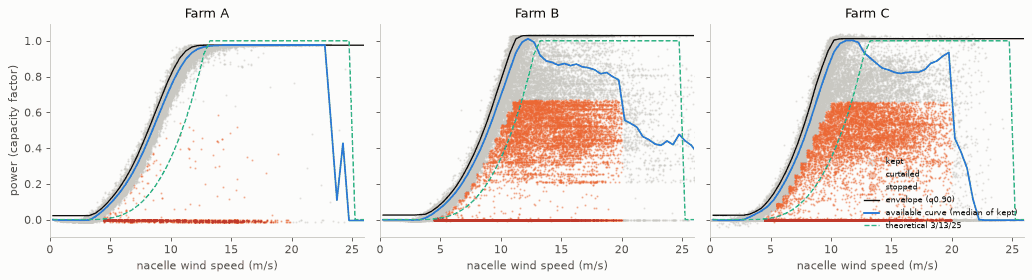

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, f in zip(axes, FARMS):
    g = D[(D["farm"] == f) & D["valid"] & ~D["event_excl"]].sample(60_000, random_state=0)
    ax.scatter(g.loc[g["clean"], "ws"], g.loc[g["clean"], "p"], s=1, c=MUTED, alpha=0.35, label="kept", rasterized=True)
    ax.scatter(g.loc[g["curtail"], "ws"], g.loc[g["curtail"], "p"], s=1, c=ORANGE, alpha=0.35, label="curtailed", rasterized=True)
    ax.scatter(g.loc[g["stop"], "ws"], g.loc[g["stop"], "p"], s=1, c=RED, alpha=0.35, label="stopped", rasterized=True)
    x = (np.arange(NBINS) + 0.5) * BIN
    ax.plot(x, ENVELOPE[f], c=INK, lw=1.2, label="envelope (q0.90)")
    ax.plot(x, REF10[f], c=BLUE, lw=1.6, label="available curve (median of kept)")
    th = np.where((x >= CUT_IN) & (x < RATED), ((x - CUT_IN) / (RATED - CUT_IN)) ** 3, np.where((x >= RATED) & (x < CUT_OUT), 1.0, 0.0))
    ax.plot(x, th, c=AQUA, lw=1.2, ls="--", label="theoretical 3/13/25")
    ax.set_xlim(0, 26)
    ax.set_title(f"Farm {f}")
    ax.set_xlabel("nacelle wind speed (m/s)")
axes[0].set_ylabel("power (capacity factor)")
axes[2].legend(loc="lower right", fontsize=7, markerscale=6, frameon=False)
fig.tight_layout()
show(fig, "power_curves_cleaning")

## 4. Hourly table and the bias of averaging wind before the power curve

The forecast is hourly, so everything is aggregated to the hour, per timeline:
- wind speed, ambient temperature, direction (circular mean), rotor speed and pitch: mean of the valid 10-minute rows;
- target `cf`: mean power of the **clean** rows, kept only when at least 4 of the 6 rows are clean;
- `cf_real`: mean power of all rows outside anomaly windows and repair (stops and curtailment included), for the
  expected-production check.

Each timeline is put on a continuous hourly index, so differences and rolling statistics never jump across a data gap.

In [10]:
D["hour"] = D["time_stamp"].dt.floor("h")
D["p_clean"] = D["p"].where(D["clean"])
D["p_real"] = D["p"].where(D["valid"] & ~D["event_excl"])
D["wd_s"] = np.sin(np.radians(D["wdir"]))
D["wd_c"] = np.cos(np.radians(D["wdir"]))
D["curve10"] = D["ref10"].where(D["clean"])
H = D.groupby(["segment", "hour"], sort=True).agg(
    ws=("ws", "mean"), ws_max=("ws_max", "max"), ws_std10=("ws_std", "mean"), amb=("amb", "mean"),
    wd_s=("wd_s", "mean"), wd_c=("wd_c", "mean"), rotor=("rotor", "mean"), pitch=("pitch", "mean"),
    cf=("p_clean", "mean"), n_clean=("clean", "sum"), cf_real=("p_real", "mean"), n_real=("p_real", "count"),
    n_rows=("p", "size"), curve_of_10min=("curve10", "mean"), p_avail=("p_avail", "mean")).reset_index()
H.loc[H["n_clean"] < MIN_ROWS_HOUR, "cf"] = np.nan
H.loc[H["n_real"] < MIN_ROWS_HOUR, "cf_real"] = np.nan
# continuous hourly index per timeline
full = []
for s, g in H.groupby("segment"):
    full.append(pd.DataFrame({"segment": s, "hour": pd.date_range(g["hour"].min(), g["hour"].max(), freq="h")}))
H = pd.concat(full, ignore_index=True).merge(H, on=["segment", "hour"], how="left")
H["turbine"] = H["segment"].str.split("-").str[0]
H["farm"] = H["turbine"].str[0]
H["group"] = H["segment"].map(GROUP)
H["day"] = (H["hour"].values.astype("datetime64[D]").astype(np.int64))
H["week"] = H["day"] // 7
H["n_rows"] = H["n_rows"].fillna(0).astype(int)
H["n_clean"] = H["n_clean"].fillna(0).astype(int)
print(f"hourly rows: {len(H):,} (with wind: {int(H['ws'].notna().sum()):,}, with a clean target: {int(H['cf'].notna().sum()):,})")
display(H.groupby("farm").agg(timelines=("segment", "nunique"), hours_with_wind=("ws", "count"), hours_with_target=("cf", "count")))

hourly rows: 810,906 (with wind: 806,304, with a clean target: 661,899)


      timelines  hours_with_wind  hours_with_target
farm                                               
A            17           169347             161620
B            14           134532             101851
C            54           502425             398428

**Averaging bias.** A power curve applied to the hourly *mean* wind is not the hourly mean of the curve applied to each
10-minute wind (Jensen: the curve is convex below about 9 m/s and concave near rated). Measured on hours whose six rows
are all clean, with each farm's 10-minute available curve:
- `curve(mean wind)` against `mean(curve(10-min wind))`: the pure averaging effect;
- both against the true hourly mean power.

       hours  mean cf  curve(mean) - mean(curve), cf  same, % of energy  curve(mean) - true, % of energy  mean(curve) - true, % of energy  largest |bias| in a 1 m/s bin, cf
farm                                                                                                                                                                        
A     159896   0.2786                        -0.0037            -1.3373                          -1.1566                           0.1807                             0.1378
B      97510   0.3511                        -0.0012            -0.3488                          -0.0324                           0.3164                             0.0835
C     373201   0.3350                        -0.0002            -0.0556                           0.2102                           0.2658                             0.0713

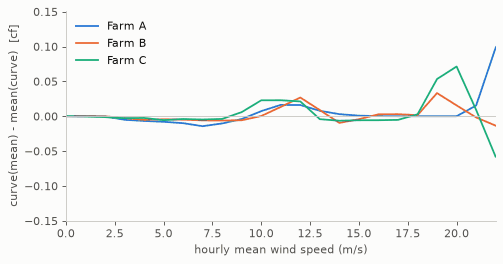

In [11]:
def curve_eval(farm, ws):
    b = np.clip(np.floor(np.nan_to_num(ws, nan=-1) / BIN).astype(int), 0, NBINS - 1)
    return np.where(np.isnan(ws), np.nan, REF10[farm].to_numpy()[b])


def theoretical(ws):
    ws = np.asarray(ws, float)
    return np.where((ws >= CUT_IN) & (ws < RATED), ((ws - CUT_IN) / (RATED - CUT_IN)) ** 3,
                    np.where((ws >= RATED) & (ws < CUT_OUT), 1.0, 0.0))


full6 = H[(H["n_clean"] == 6) & H["cf"].notna()].copy()
full6["curve_of_mean"] = np.nan
for f in FARMS:
    m = full6["farm"] == f
    full6.loc[m, "curve_of_mean"] = curve_eval(f, full6.loc[m, "ws"].to_numpy())
rows = []
for f, g in full6.groupby("farm"):
    e = g["cf"].sum()
    rows.append({"farm": f, "hours": len(g), "mean cf": g["cf"].mean(),
                 "curve(mean) - mean(curve), cf": (g["curve_of_mean"] - g["curve_of_10min"]).mean(),
                 "same, % of energy": 100 * (g["curve_of_mean"] - g["curve_of_10min"]).sum() / e,
                 "curve(mean) - true, % of energy": 100 * (g["curve_of_mean"] - g["cf"]).sum() / e,
                 "mean(curve) - true, % of energy": 100 * (g["curve_of_10min"] - g["cf"]).sum() / e,
                 "largest |bias| in a 1 m/s bin, cf": (g["curve_of_mean"] - g["curve_of_10min"]).groupby(g["ws"].round()).mean().abs().max()})
BIAS = pd.DataFrame(rows).set_index("farm").round(4)
display(BIAS)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for f, c in zip(FARMS, [BLUE, ORANGE, AQUA]):
    g = full6[full6["farm"] == f]
    b = (g["curve_of_mean"] - g["curve_of_10min"]).groupby(g["ws"].round()).mean()
    ax.plot(b.index, b.values, c=c, lw=1.6, label=f"Farm {f}")
ax.axhline(0, c=MUTED, lw=0.8)
ax.set_xlim(0, 22)
ax.set_xlabel("hourly mean wind speed (m/s)")
ax.set_ylabel("curve(mean) - mean(curve)  [cf]")
ax.legend(frameon=False)
fig.tight_layout()
show(fig, "averaging_bias")

The averaging effect is negative in the convex part of the curve (the curve of the mean under-predicts) and positive
near rated, so it largely cancels over a week; the net figure per farm is in the table above. CatBoost is trained on
hourly means against hourly targets, so it learns the hourly relationship directly and the average bias is absorbed;
the hourly variability feature (`ws_sd3`) is only a weak proxy for the variability inside the hour. The bias matters
for the physical curves applied to an hourly forecast (baselines a and b), and the forecast itself is smoother than a
nacelle hourly mean, which belongs to the forecast-error discussion in section 9.

## 5. Features and the serving contract

| feature | from `park_wind_forecast` | in CARE (training proxy) | models |
|---|---|---|---|
| `ws` | `wind_speed_100m` (m/s) | hourly mean nacelle wind speed | all |
| `ws_d1` | `wind_speed_100m`(t) - (t-1 h) | same on the hourly series | all |
| `ws_sd3` | std of `wind_speed_100m` over t-1..t+1 h | same on the hourly series | all |
| `temp` | `temperature_2m` (C) minus the park's reference temperature | ambient minus the farm median (C is shifted) | per farm, pooled |
| `wd_sin`, `wd_cos` | `wind_direction_100m` (deg) | absolute wind direction (A `sensor_1`, B `sensor_4`; C has none) | per farm A/B, pooled |
| `hod_sin`, `hod_cos` | local solar hour of `forecast_time` (UTC + longitude / 15) | hour of the timestamp | all |
| `doy_sin`, `doy_cos` | day of year of `forecast_time` | day of year | all |
| `turbine` | turbine id | CARE turbine | per farm, pooled |
| `farm` | park id | CARE farm | pooled |

Notes:
- The cube of wind speed and wind bins are **not** separate features: a tree model is invariant to monotone transforms
  of a single feature, so `ws**3` or a binned `ws` carry no extra information for CatBoost. The curves (baselines) use
  bins.
- **Gusts** have only a loose counterpart: the 10-minute maximum at the nacelle against `wind_gusts_10m` at 10 m, and
  Farm A's max/mean ratio (median 1.9) differs from B and C (1.4), so the scales do not match. A gust factor is tested as
  an ablation only (section 10).
- **Pressure, humidity and dew point** do not exist in CARE, so they cannot be learned; `wind_speed_10m` and
  `wind_direction_10m` have no hub-height counterpart.
- **Direction, turbine and farm** are site-specific: what they learn about CARE terrain, wakes and individual machines
  does not transfer to a park that is not in CARE. Hence the **generic** model below has none of them, and none of the
  temperature centring either, because centring needs a site reference.

Models (all CatBoost, fixed parameters: depth 6, at most 600 trees, learning rate 0.05, L2 10, RMSE):
- **CatBoost per farm**: one model per farm, the full forecast set plus `turbine`.
- **CatBoost pooled**: one model for all three farms, the full forecast set plus `farm` and `turbine`.
- **CatBoost generic**: one model for all three farms with only `ws`, `ws_d1`, `ws_sd3`, hour and day of year: the
  candidate for parks and turbines outside CARE.
- **SCADA complete (diagnostic, not deployable)**: per farm, forecast set plus rotor speed, pitch and the 10-minute wind
  std and max of the hour. It shows the ceiling, not something that can run seven days ahead.

In [12]:
def add_wind_features(df, key):
    """ws_d1 and ws_sd3 from the hourly wind series, computed within `key` on a continuous hourly index."""
    g = df.groupby(key, sort=False)["ws"]
    df["ws_d1"] = df["ws"] - g.shift(1)
    df["ws_sd3"] = g.transform(lambda s: s.rolling(3, center=True, min_periods=2).std())
    return df


TEMP_REF = D.groupby("farm")["amb"].median().to_dict()   # farm reference temperature (centring; C is shifted)
H = add_wind_features(H, "segment")
H["temp"] = H["amb"] - H["farm"].map(TEMP_REF)
norm = np.hypot(H["wd_s"], H["wd_c"])
H["wd_sin"] = H["wd_s"] / norm
H["wd_cos"] = H["wd_c"] / norm
hod = H["hour"].dt.hour
H["hod_sin"], H["hod_cos"] = np.sin(2 * np.pi * hod / 24), np.cos(2 * np.pi * hod / 24)
doy = H["hour"].dt.dayofyear
H["doy_sin"], H["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
H["gust"] = H["ws_max"] / np.maximum(H["ws"], 1.0)

WIND = ["ws", "ws_d1", "ws_sd3"]
TIME = ["hod_sin", "hod_cos", "doy_sin", "doy_cos"]
DIR = ["wd_sin", "wd_cos"]
FEATS = {
    "farm": {f: WIND + ["temp"] + (DIR if f != "C" else []) + TIME + ["turbine"] for f in FARMS},
    "pooled": WIND + ["temp"] + DIR + TIME + ["farm", "turbine"],
    "generic": WIND + TIME,
    "scada": {f: WIND + ["temp"] + (DIR if f != "C" else []) + TIME + ["turbine", "rotor", "pitch", "ws_std10", "ws_max"] for f in FARMS},
}
CATS = ["turbine", "farm"]
print("farm reference temperatures (C):", {k: round(v, 1) for k, v in TEMP_REF.items()})
for k, v in FEATS.items():
    print(f"{k:8s}", v if isinstance(v, list) else v["A"])

farm reference temperatures (C): {'A': 20.0, 'B': 12.6, 'C': 28.1}
farm     ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'turbine']
pooled   ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'farm', 'turbine']
generic  ['ws', 'ws_d1', 'ws_sd3', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos']
scada    ['ws', 'ws_d1', 'ws_sd3', 'temp', 'wd_sin', 'wd_cos', 'hod_sin', 'hod_cos', 'doy_sin', 'doy_cos', 'turbine', 'rotor', 'pitch', 'ws_std10', 'ws_max']


## 6. Validation schemes

- **New turbines**: the ML1 folds from `cv_folds.parquet`, seed 0. Per-farm models use the `per_farm` scheme (A and B
  leave one turbine out, C five folds), pooled and generic models the `pooled` scheme (five folds over the 36 turbines).
  A held-out turbine's id is unseen, so CatBoost falls back to its prior for it.
- **Future**: inside every timeline the first 80% of its time span trains and the last 20% tests; no hour of a test
  period is used in training.

Early stopping is internal and grouped by turbine: the training turbines are split into three groups, each group is
held out once (fits on at most 150,000 rows), and the median best iteration is used to refit on all training rows.

In [13]:
FOLDS = pd.read_parquet(FOLDS_PATH)
FOLDS = FOLDS[FOLDS["seed"] == 0]
assert set(FOLDS["turbine"]) == set(H["turbine"]), "the ML1 folds do not cover the same turbines"
FOLD_OF = {s: FOLDS[FOLDS["scheme"] == s].set_index("turbine")["fold"].to_dict() for s in ["per_farm", "pooled"]}
span = H[H["ws"].notna()].groupby("segment")["hour"].agg(["min", "max"])
cutoff = span["min"] + FUTURE_FRAC * (span["max"] - span["min"])
H["future_test"] = H["hour"] >= H["segment"].map(cutoff)
H["has_target"] = H["cf"].notna() & H["ws"].notna()
H["has_input"] = H["ws"].notna()
display(FOLDS.groupby(["scheme", "farm"])["fold"].nunique().unstack())
print("future scheme, hours with target: train", int((H["has_target"] & ~H["future_test"]).sum()),
      "test", int((H["has_target"] & H["future_test"]).sum()))

farm      A  B  C
scheme           
per_farm  5  9  5
pooled    5  5  5

future scheme, hours with target: train 543591 test 118308


**Park-wide inputs.** In CARE every turbine has its own nacelle wind. At serving every turbine of a park gets the *same*
forecast row. To reproduce that, each hour of a time group gets the median wind (and the group's median temperature and
mean direction) of all its turbines, the derived wind features are recomputed on that park series, and the fitted models
predict again. With identical weather inputs the only thing that can separate two turbines is what the model knows about
the turbine itself.

One extra model is **trained** on these park-wide inputs (target = the turbine's own power): `CatBoost per farm, park
wind`. It is the faithful version of the serving situation, one weather row per park and hour, and its turbine id has
to learn how each machine's output differs from what the park weather alone implies (position in the park, wakes,
machine). Its "park wind" column is the one that matters.

In [14]:
def park_frame(src, ws_noise=None):
    G = src[src["has_input"]].groupby(["group", "hour"]).agg(ws=("ws", "median"), temp=("temp", "median"),
                                                              wd_s=("wd_s", "mean"), wd_c=("wd_c", "mean")).reset_index()
    full = [pd.DataFrame({"group": g, "hour": pd.date_range(d["hour"].min(), d["hour"].max(), freq="h")}) for g, d in G.groupby("group")]
    G = pd.concat(full, ignore_index=True).merge(G, on=["group", "hour"], how="left")
    if ws_noise is not None:
        G["ws"] = np.maximum(G["ws"] + ws_noise(G), 0.0)
    G = add_wind_features(G, "group")
    n = np.hypot(G["wd_s"], G["wd_c"])
    G["wd_sin"], G["wd_cos"] = G["wd_s"] / n, G["wd_c"] / n
    cols = ["ws", "ws_d1", "ws_sd3", "temp", "wd_sin", "wd_cos"]
    out = src.drop(columns=cols).merge(G[["group", "hour"] + cols], on=["group", "hour"], how="left")
    out.index = src.index
    return out


HP = park_frame(H)
SRC = {"own": H, "park": HP}
print("park-wide inputs built; wind of a turbine vs its park median, hourly correlation:",
      round(float(np.corrcoef(H.loc[H["has_input"], "ws"], HP.loc[H["has_input"], "ws"])[0, 1]), 3))

park-wide inputs built; wind of a turbine vs its park median, hourly correlation: 0.99


## 7. Models and baselines

Every model and baseline runs through the same splits and is scored on the same hours.

Baselines:
- **(a) theoretical curve**: 0 below 3 m/s, `((ws - 3) / 10) ** 3` up to 13 m/s, 1 up to 25 m/s, 0 above (the shape
  `smarthack/wind` uses), applied to the hourly wind.
- **(b) empirical curve**: per farm, the median hourly target per 0.5 m/s bin of hourly wind on the training rows (bins
  with at least 20 hours), linearly interpolated. **This is the bar CatBoost has to clear.** A mean-per-bin variant is
  shown too, because the median is not the energy-optimal statistic.
- **(c) climatology**: mean target per turbine and hour of day on the training rows (farm and hour for an unseen turbine).
- **Future scheme only**: an empirical median curve per turbine (farm curve where a turbine bin is empty), the natural
  competitor of a model that knows the turbine.

In [15]:
assert (H.index == np.arange(len(H))).all()


def frame(df, feats):
    X = df[feats].copy()
    for c in CATS:
        if c in X:
            X[c] = X[c].astype(str)
    return X


def inner_groups(turbines, seed, n=3):
    t = np.array(sorted(turbines))
    np.random.default_rng(1000 + seed).shuffle(t)
    k = min(n, len(t))
    return [t[i::k] for i in range(k)]


def subsample(idx, n, rng):
    return idx if len(idx) <= n else np.sort(rng.choice(idx, n, replace=False))


def fit_catboost(tr, feats, iterations=None):
    """Fit on the training rows; without `iterations`, the tree count comes from inner early stopping grouped by turbine."""
    rng = np.random.default_rng(SEED)
    cats = [c for c in feats if c in CATS]
    X, y = frame(tr, feats), tr["cf"].to_numpy()
    if FAST:
        keep = subsample(np.arange(len(tr)), 60_000, rng)
        X, y, tr = X.iloc[keep], y[keep], tr.iloc[keep]
    inner = []
    if iterations is None:
        turbs = tr["turbine"].to_numpy()
        for g in inner_groups(np.unique(turbs), SEED):
            ev = np.isin(turbs, g)
            i_fit = subsample(np.flatnonzero(~ev), INNER_MAX_ROWS, rng)
            i_ev = subsample(np.flatnonzero(ev), INNER_MAX_ROWS // 2, rng)
            m = CatBoostRegressor(**CB_PARAMS)
            m.fit(X.iloc[i_fit], y[i_fit], cat_features=cats, eval_set=(X.iloc[i_ev], y[i_ev]), early_stopping_rounds=50,
                  use_best_model=False)
            inner.append(m.get_best_iteration() + 1)
        iterations = int(max(50, np.median(inner)))
    m = CatBoostRegressor(**{**CB_PARAMS, "iterations": iterations})
    m.fit(X, y, cat_features=cats)
    return m, iterations, inner


def fit_curve(ws, y, stat):
    b = np.floor(ws / BIN).astype(int)
    s = pd.Series(y).groupby(b)
    v = s.median() if stat == "median" else s.mean()
    v = v[s.size() >= 20]
    return ((v.index.to_numpy() + 0.5) * BIN, v.to_numpy())


def eval_curve(c, ws):
    return np.interp(np.nan_to_num(ws, nan=0.0), c[0], c[1])


class CurvePerTurbine:
    """Median curve per turbine on 0.5 m/s bins; bins with fewer than 20 hours take the farm curve."""

    def __init__(self, tr):
        centres = (np.arange(NBINS) + 0.5) * BIN
        self.centres = centres
        self.curves = {}
        farm = {f: fit_curve(g["ws"].to_numpy(), g["cf"].to_numpy(), "median") for f, g in tr.groupby("farm")}
        self.farm = {f: eval_curve(c, centres) for f, c in farm.items()}
        for t, g in tr.groupby("turbine"):
            b = np.floor(g["ws"].to_numpy() / BIN).astype(int)
            s = pd.Series(g["cf"].to_numpy()).groupby(b)
            v = s.median()[s.size() >= 20]
            v = v[(v.index >= 0) & (v.index < NBINS)]
            curve = self.farm[t[0]].copy()
            curve[v.index.to_numpy()] = v.to_numpy()
            self.curves[t] = curve

    def __call__(self, df):
        out = np.empty(len(df))
        ws = np.nan_to_num(df["ws"].to_numpy(), nan=0.0)
        for (t, f), i in df.groupby(["turbine", "farm"]).indices.items():
            out[i] = np.interp(ws[i], self.centres, self.curves.get(t, self.farm[f]))
        return out


class Climatology:
    def __init__(self, tr):
        h = tr["hour"].dt.hour
        self.t = tr.groupby([tr["turbine"], h])["cf"].mean().to_dict()
        self.f = tr.groupby([tr["farm"], h])["cf"].mean().to_dict()

    def __call__(self, df):
        h = df["hour"].dt.hour.to_numpy()
        return np.array([self.t.get((t, x), self.f.get((f, x), np.nan)) for t, f, x in zip(df["turbine"], df["farm"], h)])


def splits(scheme, farms, fold_scheme):
    sub = H.index[H["farm"].isin(farms)]
    if scheme == "new":
        fo = H.loc[sub, "turbine"].map(FOLD_OF[fold_scheme])
        for k in sorted(fo.unique()):
            yield k, sub[(fo != k).to_numpy()], sub[(fo == k).to_numpy()]
    else:
        ft = H.loc[sub, "future_test"].to_numpy()
        yield 0, sub[~ft], sub[ft]


CB_MODELS = {   # name -> (feature set, farms trained together, fold scheme, fixed iterations, training inputs)
    "CatBoost per farm": ("farm", "each", "per_farm", None, "own"),
    "CatBoost per farm, park wind": ("farm", "each", "per_farm", None, "park"),
    "CatBoost pooled": ("pooled", "all", "pooled", None, "own"),
    "CatBoost generic": ("generic", "all", "pooled", None, "own"),
    "SCADA complete (diagnostic)": ("scada", "each", "per_farm", 600, "own"),
}
BASELINES = ["theoretical curve", "empirical curve (median)", "empirical curve (mean)", "climatology (turbine x hour)"]
FITTED = {}    # (scheme, model) -> list of (test index, predict function)
ITERS = []


def run_all():
    for scheme in ["new", "future"]:
        for name, (fs, together, fold_scheme, fixed, inputs) in CB_MODELS.items():
            groups = [[f] for f in FARMS] if together == "each" else [FARMS]
            FITTED[(scheme, name)] = []
            for farms in groups:
                feats = FEATS[fs][farms[0]] if isinstance(FEATS[fs], dict) else FEATS[fs]
                for k, tr_idx, te_idx in splits(scheme, farms, fold_scheme):
                    tr = SRC[inputs].loc[tr_idx]
                    tr = tr[tr["has_target"] & tr["ws"].notna()]
                    t1 = time.time()
                    m, n_it, inner = fit_catboost(tr, feats, fixed)
                    ITERS.append(dict(scheme=scheme, model=name, farms="".join(farms), fold=k, iterations=n_it, inner=inner,
                                      train_rows=len(tr), seconds=round(time.time() - t1, 1)))
                    te = te_idx[H.loc[te_idx, "has_input"].to_numpy()]
                    FITTED[(scheme, name)].append((te, lambda df, m=m, feats=feats: m.predict(frame(df, feats))))
        # baselines, per farm, on the per-farm folds (new) or the future split
        for name in BASELINES + (["empirical curve per turbine (median)"] if scheme == "future" else []):
            FITTED[(scheme, name)] = []
        for f in FARMS:
            for k, tr_idx, te_idx in splits(scheme, [f], "per_farm"):
                tr = H.loc[tr_idx]
                tr = tr[tr["has_target"]]
                te = te_idx[H.loc[te_idx, "has_input"].to_numpy()]
                med = fit_curve(tr["ws"].to_numpy(), tr["cf"].to_numpy(), "median")
                mean = fit_curve(tr["ws"].to_numpy(), tr["cf"].to_numpy(), "mean")
                FITTED[(scheme, "theoretical curve")].append((te, lambda df: theoretical(df["ws"].to_numpy())))
                FITTED[(scheme, "empirical curve (median)")].append((te, lambda df, c=med: eval_curve(c, df["ws"].to_numpy())))
                FITTED[(scheme, "empirical curve (mean)")].append((te, lambda df, c=mean: eval_curve(c, df["ws"].to_numpy())))
                FITTED[(scheme, "climatology (turbine x hour)")].append((te, Climatology(tr)))
                if scheme == "future":
                    FITTED[(scheme, "empirical curve per turbine (median)")].append((te, CurvePerTurbine(tr)))


def predict_all(src, scheme, models=None):
    """Predictions of every fitted model of a scheme on the rows of `src` (same index as H, inputs possibly modified)."""
    out = {}
    for (s, name), parts in FITTED.items():
        if s != scheme or (models is not None and name not in models):
            continue
        p = np.full(len(src), np.nan)
        for te, fn in parts:
            p[te] = fn(src.loc[te])
        out[name] = p
    return pd.DataFrame(out, index=src.index)


t_run = time.time()
run_all()
ITERS = pd.DataFrame(ITERS)
PRED = {s: predict_all(H, s) for s in ["new", "future"]}
PRED_PARK = {s: predict_all(HP, s) for s in ["new", "future"]}
print(f"models fitted in {time.time() - t_run:.0f} s")
display(ITERS.groupby(["scheme", "model", "farms"]).agg(folds=("fold", "size"), median_trees=("iterations", "median"),
                                                         train_rows=("train_rows", "median"), seconds=("seconds", "sum")))

models fitted in 661 s


                                           folds  median_trees  train_rows  seconds
scheme model                        farms                                          
future CatBoost generic             ABC        1         600.0    543591.0     10.8
       CatBoost per farm            A          1         216.0    131049.0      7.2
                                    B          1         595.0     84089.0     10.7
                                    C          1         276.0    328453.0     13.3
       CatBoost per farm, park wind A          1          83.0    131049.0      2.6
                                    B          1         458.0     84089.0      8.9
                                    C          1         156.0    328453.0      6.4
       CatBoost pooled              ABC        1         167.0    543591.0     13.4
       SCADA complete (diagnostic)  A          1         600.0    131049.0      4.5
                                    B          1         600.0     84089.0  

## 8. Results

Metrics, all on hours with a clean target:
- **hourly**: MAE, RMSE, R2 and bias in capacity-factor units;
- **7-day energy**: per timeline and calendar week with at least 120 clean hours, energy = sum of hourly capacity factor
  on those hours (capacity-factor hours; MWh = that x capacity_kw / 1000). WAPE = sum |error| / sum of true energy, the
  median absolute relative error, and the energy bias;
- **decision**: for every pair of different turbines in the same time group and the same calendar week, with at least
  120 clean hours in common, energy on the common hours. Pair accuracy = share of pairs where the model orders them like
  the truth (a tie counts one half). Shown with own wind and with park-wide wind (the serving situation), plus the
  accuracy on pairs whose true gap is at least 5%, and the Spearman correlation inside windows with three or more
  turbines and at least 72 common hours.
- 95% intervals: cluster bootstrap over turbines, 1000 resamples, the same resamples for every model of a farm
  (Spearman: bootstrap over windows).

In [16]:
def boot_matrix(units, seed):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(units), size=(N_BOOT, len(units)))
    W = np.zeros((N_BOOT, len(units)))
    np.add.at(W, (np.repeat(np.arange(N_BOOT), len(units)), idx.ravel()), 1)
    return W


def ci(v):
    return np.nanpercentile(v, [2.5, 97.5])


def hourly_metrics(y, p, turb, units, W):
    d = pd.DataFrame({"t": turb, "e": p - y, "ae": np.abs(p - y), "se2": (p - y) ** 2, "y": y, "y2": y ** 2})
    S = d.groupby("t").agg(n=("e", "size"), se=("e", "sum"), sae=("ae", "sum"), sse=("se2", "sum"), sy=("y", "sum"),
                           syy=("y2", "sum")).reindex(units).fillna(0).to_numpy()

    def calc(w):
        tot = w @ S
        n, se, sae, sse, sy, syy = (tot[..., i] for i in range(6))
        return dict(mae=sae / n, rmse=np.sqrt(sse / n), r2=1 - sse / (syy - sy ** 2 / n), bias=se / n)

    pt, bt = calc(np.ones(len(units))), calc(W)
    return {k: (float(pt[k]), *ci(bt[k])) for k in pt}


def weekly_table(df, pcol):
    g = df.groupby(["segment", "week"])
    w = pd.DataFrame({"n": g.size(), "E": g["cf"].sum(), "P": g[pcol].sum()}).reset_index()
    w = w[w["n"] >= WEEK_MIN_HOURS]
    w["turbine"] = w["segment"].str.split("-").str[0]
    return w


def energy_metrics(w, units, W):
    w = w.assign(ae=(w["P"] - w["E"]).abs(), e=w["P"] - w["E"])
    S = w.groupby("turbine").agg(ae=("ae", "sum"), e=("e", "sum"), E=("E", "sum")).reindex(units).fillna(0).to_numpy()
    pt = S.sum(0)
    bt = W @ S
    rel = (w["P"] - w["E"]).abs() / w["E"].clip(lower=1e-6)
    return dict(wape=(pt[0] / pt[2], *ci(bt[:, 0] / bt[:, 2])), ebias=(pt[1] / pt[2], *ci(bt[:, 1] / bt[:, 2])),
                med_rel=float(rel.median()), weeks=len(w))


def build_pairs(mask):
    """Pairs of timelines of different turbines in the same time group and week, with their common clean hours."""
    d = H.loc[mask, ["group", "week", "segment", "turbine", "hour"]]
    rows_a, rows_b, meta = [], [], []
    for (g, wk), x in d.groupby(["group", "week"]):
        segs = x["segment"].unique()
        if len(segs) < 2:
            continue
        by = {s: pd.Series(x.index[x["segment"] == s], index=x.loc[x["segment"] == s, "hour"]) for s in segs}
        for a, b in combinations(sorted(segs), 2):
            if a.split("-")[0] == b.split("-")[0]:
                continue
            common = by[a].index.intersection(by[b].index)
            if len(common) < WEEK_MIN_HOURS:
                continue
            pid = len(meta)
            rows_a.append(np.column_stack([np.full(len(common), pid), by[a].loc[common].to_numpy()]))
            rows_b.append(by[b].loc[common].to_numpy())
            meta.append(dict(group=g, week=wk, farm=g[0], seg_a=a, seg_b=b, turb_a=a.split("-")[0], turb_b=b.split("-")[0],
                             hours=len(common)))
    ra = np.vstack(rows_a)
    return dict(pid=ra[:, 0], ia=ra[:, 1], ib=np.concatenate(rows_b), meta=pd.DataFrame(meta))


def build_windows(mask, min_turbines=3, min_hours=72):
    d = H.loc[mask, ["group", "week", "segment", "turbine", "hour"]]
    out = []
    for (g, wk), x in d.groupby(["group", "week"]):
        if x["turbine"].nunique() < min_turbines:
            continue
        piv = x.reset_index().pivot_table(index="hour", columns="segment", values="index", aggfunc="first").dropna()
        if len(piv) < min_hours or piv.shape[1] < min_turbines:
            continue
        out.append(dict(group=g, week=wk, farm=g[0], idx=piv.to_numpy().astype(int).T))
    return out


def pair_scores(P, y, pairs):
    Ea = np.bincount(pairs["pid"], weights=y[pairs["ia"]])
    Eb = np.bincount(pairs["pid"], weights=y[pairs["ib"]])
    Pa = np.bincount(pairs["pid"], weights=P[pairs["ia"]])
    Pb = np.bincount(pairs["pid"], weights=P[pairs["ib"]])
    dt, dp = Ea - Eb, Pa - Pb
    tie = np.abs(dp) < 1e-9 * np.maximum(np.abs(Pa), 1)
    score = np.where(tie, 0.5, (np.sign(dt) == np.sign(dp)).astype(float))
    gap = np.abs(dt) / np.maximum((Ea + Eb) / 2, 1e-6)
    return score, gap


def pair_metrics(score, gap, meta, units, W):
    ui = {u: i for i, u in enumerate(units)}
    a, b = meta["turb_a"].map(ui).to_numpy(), meta["turb_b"].map(ui).to_numpy()
    w = W[:, a] * W[:, b]
    big = gap >= 0.05
    acc_b = (w * score).sum(1) / w.sum(1)
    big_b = (w[:, big] * score[big]).sum(1) / w[:, big].sum(1)
    return dict(acc=(float(score.mean()), *ci(acc_b)), acc_big=(float(score[big].mean()) if big.any() else np.nan, *ci(big_b)),
                pairs=len(score), big_share=float(big.mean()), median_gap=float(np.median(gap)))


def spearman_windows(P, y, windows, seed=0):
    vals = []
    for w in windows:
        t = y[w["idx"]].mean(1)
        p = P[w["idx"]].mean(1)
        vals.append(spearmanr(p, t)[0] if np.ptp(p) > 0 else 0.0)
    vals = np.nan_to_num(np.array(vals))
    if len(vals) == 0:
        return (np.nan, np.nan, np.nan), 0
    rng = np.random.default_rng(seed)
    bt = vals[rng.integers(0, len(vals), size=(N_BOOT, len(vals)))].mean(1)
    return (float(vals.mean()), *ci(bt)), len(vals)


UNITS = {f: sorted(H.loc[H["farm"] == f, "turbine"].unique()) for f in FARMS}
BOOTW = {f: boot_matrix(UNITS[f], seed=100 + i) for i, f in enumerate(FARMS)}
EVAL_MASK = {"new": H["has_target"].to_numpy(), "future": (H["has_target"] & H["future_test"]).to_numpy()}
PAIRS = {s: build_pairs(EVAL_MASK[s]) for s in ["new", "future"]}
WINDOWS = {s: build_windows(EVAL_MASK[s]) for s in ["new", "future"]}
Y = H["cf"].to_numpy()
for s in ["new", "future"]:
    m = PAIRS[s]["meta"]
    print(f"{s}: pairs per farm {m.groupby('farm').size().to_dict()}, windows with 3+ turbines "
          f"{pd.Series([w['farm'] for w in WINDOWS[s]]).value_counts().sort_index().to_dict()}")


def evaluate(scheme, pred, pred_park, models=None):
    rows = []
    for name in pred.columns if models is None else models:
        P, PP = pred[name].to_numpy(), pred_park[name].to_numpy()
        for f in FARMS:
            m = EVAL_MASK[scheme] & (H["farm"] == f).to_numpy() & ~np.isnan(P)
            if m.sum() == 0:
                continue
            hm = hourly_metrics(Y[m], P[m], H["turbine"].to_numpy()[m], UNITS[f], BOOTW[f])
            wk = weekly_table(H.loc[m, ["segment", "week", "cf"]].assign(pred=P[m]), "pred")
            em = energy_metrics(wk, UNITS[f], BOOTW[f])
            pr = PAIRS[scheme]
            sel = (pr["meta"]["farm"] == f).to_numpy()
            keep = np.isin(pr["pid"], np.flatnonzero(sel))
            sub = dict(pid=pd.factorize(pr["pid"][keep])[0], ia=pr["ia"][keep], ib=pr["ib"][keep])
            meta = pr["meta"][sel].reset_index(drop=True)
            r = {"scheme": scheme, "farm": f, "model": name, "R2": hm["r2"], "MAE": hm["mae"], "RMSE": hm["rmse"],
                 "bias": hm["bias"], "WAPE 7d": em["wape"], "energy bias 7d": em["ebias"], "median |rel err| 7d": em["med_rel"],
                 "weeks": em["weeks"]}
            for mode, PX in [("own wind", P), ("park wind", PP)]:
                sc, gap = pair_scores(np.nan_to_num(PX), Y, sub)
                pm = pair_metrics(sc, gap, meta, UNITS[f], BOOTW[f])
                r[f"pair acc ({mode})"] = pm["acc"]
                r[f"pair acc gap>=5% ({mode})"] = pm["acc_big"]
                win = [w for w in WINDOWS[scheme] if w["farm"] == f]
                sp, nw = spearman_windows(np.nan_to_num(PX), Y, win)
                r[f"Spearman ({mode})"] = sp
            r["pairs"], r["median true gap"], r["windows 3+"] = pm["pairs"], pm["median_gap"], nw
            rows.append(r)
    return pd.DataFrame(rows)


def fmt(v, d=3):
    if isinstance(v, tuple):
        return f"{v[0]:.{d}f} [{v[1]:.{d}f}, {v[2]:.{d}f}]" if not np.isnan(v[0]) else "-"
    return f"{v:.{d}f}" if isinstance(v, float) else v


def point(v):
    return v[0] if isinstance(v, tuple) else v


t_ev = time.time()
RES = pd.concat([evaluate(s, PRED[s], PRED_PARK[s]) for s in ["new", "future"]], ignore_index=True)
print(f"evaluated in {time.time() - t_ev:.0f} s")
MODEL_ORDER = list(CB_MODELS) + BASELINES + ["empirical curve per turbine (median)"]
RES["order"] = RES["model"].map({m: i for i, m in enumerate(MODEL_ORDER)})
RES = RES.sort_values(["scheme", "farm", "order"], ascending=[False, True, True]).drop(columns="order").reset_index(drop=True)

new: pairs per farm {'A': 756, 'B': 119, 'C': 2363}, windows with 3+ turbines {'A': 142, 'C': 308}
future: pairs per farm {'A': 59, 'B': 10, 'C': 94}, windows with 3+ turbines {'A': 7, 'C': 24}


evaluated in 4 s


### 8.1 Hourly accuracy and 7-day energy

In [17]:
for s, title in [("new", "NEW TURBINES (ML1 folds)"), ("future", "FUTURE (last 20% of every timeline)")]:
    t = RES[RES["scheme"] == s]
    print(f"=== {title}")
    display(pd.DataFrame({"farm": t["farm"], "model": t["model"], "R2 [95% CI]": t["R2"].map(fmt),
                          "MAE": t["MAE"].map(lambda v: f"{v[0]:.4f}"), "RMSE": t["RMSE"].map(lambda v: f"{v[0]:.4f}"),
                          "bias": t["bias"].map(lambda v: f"{v[0]:+.4f}"), "WAPE 7d [95% CI]": t["WAPE 7d"].map(fmt),
                          "energy bias 7d": t["energy bias 7d"].map(lambda v: f"{v[0]:+.3f}"),
                          "median |rel err| 7d": t["median |rel err| 7d"].map(lambda v: f"{v:.3f}"), "weeks": t["weeks"]}).set_index(["farm", "model"]))

=== NEW TURBINES (ML1 folds)


                                              R2 [95% CI]     MAE    RMSE     bias      WAPE 7d [95% CI] energy bias 7d median |rel err| 7d  weeks
farm model                                                                                                                                        
A    CatBoost per farm               0.994 [0.992, 0.995]  0.0156  0.0258  +0.0015  0.032 [0.019, 0.045]         +0.005               0.030    966
     CatBoost per farm, park wind    0.990 [0.988, 0.993]  0.0224  0.0325  -0.0005  0.044 [0.033, 0.052]         -0.002               0.041    966
     CatBoost pooled                 0.992 [0.990, 0.994]  0.0183  0.0295  -0.0069  0.043 [0.032, 0.057]         -0.025               0.047    966
     CatBoost generic                0.990 [0.986, 0.993]  0.0191  0.0319  +0.0062  0.036 [0.020, 0.057]         +0.022               0.031    966
     SCADA complete (diagnostic)     0.996 [0.993, 0.998]  0.0141  0.0217  +0.0052  0.034 [0.019, 0.050]         +0.01

=== FUTURE (last 20% of every timeline)


                                                       R2 [95% CI]     MAE    RMSE     bias      WAPE 7d [95% CI] energy bias 7d median |rel err| 7d  weeks
farm model                                                                                                                                                 
A    CatBoost per farm                        0.997 [0.996, 0.997]  0.0102  0.0184  -0.0010  0.013 [0.009, 0.018]         -0.003               0.012    179
     CatBoost per farm, park wind             0.994 [0.992, 0.996]  0.0155  0.0256  -0.0003  0.023 [0.020, 0.027]         -0.002               0.022    179
     CatBoost pooled                          0.996 [0.995, 0.996]  0.0127  0.0215  -0.0009  0.015 [0.011, 0.020]         -0.003               0.013    179
     CatBoost generic                         0.991 [0.988, 0.993]  0.0191  0.0308  +0.0066  0.033 [0.018, 0.050]         +0.022               0.028    179
     SCADA complete (diagnostic)              0.998 [0.998, 0.99

### 8.2 Ordering turbines of the same park (the decision ML2 serves)

In [18]:
for s, title in [("new", "NEW TURBINES"), ("future", "FUTURE")]:
    t = RES[RES["scheme"] == s]
    print(f"=== {title}")
    display(pd.DataFrame({"farm": t["farm"], "model": t["model"],
                          "pair acc, own wind [CI]": t["pair acc (own wind)"].map(fmt),
                          "pair acc, park wind [CI]": t["pair acc (park wind)"].map(fmt),
                          "gap>=5%, own": t["pair acc gap>=5% (own wind)"].map(lambda v: f"{v[0]:.3f}"),
                          "gap>=5%, park": t["pair acc gap>=5% (park wind)"].map(lambda v: f"{v[0]:.3f}"),
                          "Spearman own": t["Spearman (own wind)"].map(lambda v: f"{v[0]:.2f}"),
                          "Spearman park": t["Spearman (park wind)"].map(lambda v: f"{v[0]:.2f}"),
                          "pairs": t["pairs"], "median true gap": t["median true gap"].map(lambda v: f"{v:.3f}"),
                          "windows 3+": t["windows 3+"]}).set_index(["farm", "model"]))

=== NEW TURBINES


                                  pair acc, own wind [CI] pair acc, park wind [CI] gap>=5%, own gap>=5%, park Spearman own Spearman park  pairs median true gap  windows 3+
farm model                                                                                                                                                                 
A    CatBoost per farm               0.800 [0.648, 0.958]     0.452 [0.293, 0.734]        0.886         0.434         0.58         -0.19    756           0.076         142
     CatBoost per farm, park wind    0.765 [0.638, 0.940]     0.299 [0.189, 0.422]        0.844         0.243         0.49         -0.42    756           0.076         142
     CatBoost pooled                 0.784 [0.638, 0.942]     0.323 [0.160, 0.475]        0.876         0.276         0.54         -0.38    756           0.076         142
     CatBoost generic                0.804 [0.705, 0.933]     0.361 [0.234, 0.517]        0.903         0.346         0.62         -0.30    

=== FUTURE


                                          pair acc, own wind [CI] pair acc, park wind [CI] gap>=5%, own gap>=5%, park Spearman own Spearman park  pairs median true gap  windows 3+
farm model                                                                                                                                                                         
A    CatBoost per farm                       0.966 [0.889, 1.000]     0.627 [0.167, 0.905]        1.000         0.676         1.00          0.36     59           0.074           7
     CatBoost per farm, park wind            0.966 [0.875, 1.000]     0.797 [0.739, 0.900]        1.000         0.811         1.00          0.79     59           0.074           7
     CatBoost pooled                         0.966 [0.897, 1.000]     0.610 [0.125, 0.905]        0.973         0.676         0.93          0.36     59           0.074           7
     CatBoost generic                        0.915 [0.846, 1.000]     0.500 [0.500, 0.500]        1.

### 8.3 CatBoost against the empirical curve (paired bootstrap over turbines)

Difference in R2, WAPE and pair accuracy (own wind), CatBoost minus the empirical median curve, on the same resamples.

In [19]:
def paired_diff(scheme, model, base="empirical curve (median)"):
    rows = []
    for f in FARMS:
        m = EVAL_MASK[scheme] & (H["farm"] == f).to_numpy()
        A_, B_ = PRED[scheme][model].to_numpy(), PRED[scheme][base].to_numpy()
        m &= ~np.isnan(A_) & ~np.isnan(B_)
        turb = H["turbine"].to_numpy()[m]
        out = {}
        for nm, P in [("a", A_), ("b", B_)]:
            d = pd.DataFrame({"t": turb, "se2": (P[m] - Y[m]) ** 2, "y": Y[m], "y2": Y[m] ** 2})
            S = d.groupby("t").agg(n=("y", "size"), sse=("se2", "sum"), sy=("y", "sum"), syy=("y2", "sum")).reindex(UNITS[f]).fillna(0).to_numpy()
            tot = BOOTW[f] @ S
            out[nm] = 1 - tot[:, 1] / (tot[:, 3] - tot[:, 2] ** 2 / tot[:, 0])
            wk = weekly_table(H.loc[m, ["segment", "week", "cf"]].assign(pred=P[m]), "pred")
            wk = wk.assign(ae=(wk["P"] - wk["E"]).abs())
            S2 = wk.groupby("turbine").agg(ae=("ae", "sum"), E=("E", "sum")).reindex(UNITS[f]).fillna(0).to_numpy()
            t2 = BOOTW[f] @ S2
            out[nm + "_w"] = t2[:, 0] / t2[:, 1]
        r2d, wd = out["a"] - out["b"], out["a_w"] - out["b_w"]
        rows.append({"scheme": scheme, "farm": f, "model": model, "R2 difference [CI]": f"{np.median(r2d):+.3f} [{ci(r2d)[0]:+.3f}, {ci(r2d)[1]:+.3f}]",
                     "WAPE difference [CI]": f"{np.median(wd):+.3f} [{ci(wd)[0]:+.3f}, {ci(wd)[1]:+.3f}]",
                     "beats the curve on R2": bool(ci(r2d)[0] > 0), "beats the curve on WAPE": bool(ci(wd)[1] < 0)})
    return rows


PAIRED = pd.DataFrame([r for s in ["new", "future"] for mdl in ["CatBoost per farm", "CatBoost pooled", "CatBoost generic"]
                       for r in paired_diff(s, mdl)])
display(PAIRED.set_index(["scheme", "farm", "model"]))

                                    R2 difference [CI]     WAPE difference [CI]  beats the curve on R2  beats the curve on WAPE
scheme farm model                                                                                                              
new    A    CatBoost per farm  +0.001 [+0.001, +0.002]  -0.008 [-0.014, -0.003]                   True                     True
       B    CatBoost per farm  +0.012 [+0.005, +0.017]  -0.006 [-0.013, -0.000]                   True                     True
       C    CatBoost per farm  +0.003 [-0.001, +0.006]  +0.011 [+0.000, +0.020]                  False                    False
       A    CatBoost pooled    -0.001 [-0.002, +0.001]  +0.004 [-0.010, +0.019]                  False                    False
       B    CatBoost pooled    +0.005 [+0.003, +0.007]  -0.006 [-0.011, -0.002]                   True                     True
       C    CatBoost pooled    +0.003 [-0.000, +0.007]  +0.012 [+0.001, +0.020]                  False  

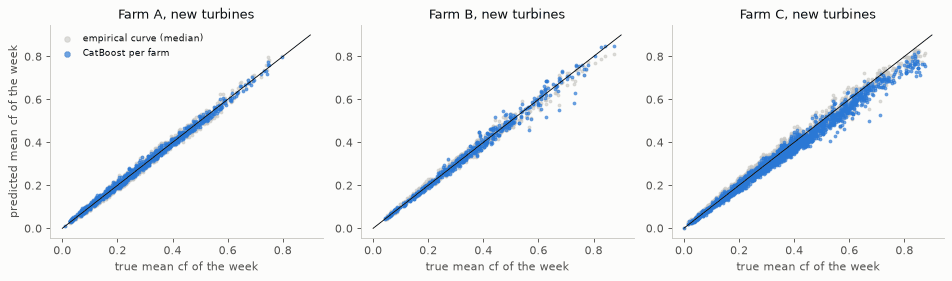

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, f in zip(axes, FARMS):
    m = EVAL_MASK["new"] & (H["farm"] == f).to_numpy()
    for name, c in [("empirical curve (median)", MUTED), ("CatBoost per farm", BLUE)]:
        wk = weekly_table(H.loc[m, ["segment", "week", "cf"]].assign(pred=PRED["new"][name].to_numpy()[m]), "pred")
        ax.scatter(wk["E"] / wk["n"], wk["P"] / wk["n"], s=6, c=c, alpha=0.6, label=name)
    ax.plot([0, 0.9], [0, 0.9], c=INK, lw=0.8)
    ax.set_title(f"Farm {f}, new turbines")
    ax.set_xlabel("true mean cf of the week")
axes[0].set_ylabel("predicted mean cf of the week")
axes[0].legend(frameon=False, fontsize=8, markerscale=2)
fig.tight_layout()
show(fig, "weekly_energy_new_turbines")

### 8.4 Expected production: available x availability against what the turbine really produced

Future scheme. Each turbine's availability is measured on its training period (first 80%), then applied to the test
weeks: `expected = CatBoost per farm (available) x availability`, against the realized energy (all rows outside anomaly
windows, stops and curtailment included), on hours where the realized power exists.

In [21]:
cut_hour = D["segment"].map(cutoff)
AVAIL_TRAIN = availability(D[D["hour"] < cut_hour])
real_rows = (H["cf_real"].notna() & H["has_input"] & H["future_test"]).to_numpy()
rows = []
for f in FARMS:
    m = real_rows & (H["farm"] == f).to_numpy()
    d = H.loc[m, ["segment", "turbine", "week", "cf_real"]].copy()
    d["avail_pred"] = PRED["future"]["CatBoost per farm"].to_numpy()[m]
    d["expected"] = d["avail_pred"] * d["turbine"].map(AVAIL_TRAIN["availability"])
    g = d.groupby(["segment", "week"]).agg(n=("cf_real", "size"), real=("cf_real", "sum"), avail=("avail_pred", "sum"), exp=("expected", "sum"))
    g = g[g["n"] >= WEEK_MIN_HOURS]
    rows.append({"farm": f, "weeks": len(g), "WAPE: available vs realized": (g["avail"] - g["real"]).abs().sum() / g["real"].sum(),
                 "bias: available vs realized": (g["avail"] - g["real"]).sum() / g["real"].sum(),
                 "WAPE: expected vs realized": (g["exp"] - g["real"]).abs().sum() / g["real"].sum(),
                 "bias: expected vs realized": (g["exp"] - g["real"]).sum() / g["real"].sum(),
                 "median availability (train)": AVAIL_TRAIN.loc[AVAIL_TRAIN.index.str[0] == f, "availability"].median()})
EXPECTED = pd.DataFrame(rows).set_index("farm").round(3)
display(EXPECTED)

      weeks  WAPE: available vs realized  bias: available vs realized  WAPE: expected vs realized  bias: expected vs realized  median availability (train)
farm                                                                                                                                                      
A       180                        0.035                        0.022                       0.054                      -0.027                        0.945
B       113                        0.158                        0.156                       0.155                      -0.090                        0.792
C       511                        0.294                        0.286                       0.204                       0.007                        0.783

## 9. Forecast-error sensitivity

Everything above uses the wind **measured** at the nacelle. At serving the input is the wind **forecast** at 100 m, with
an error that grows with lead time. The CARE numbers are therefore an upper bound. To see how fast they fall, the test
wind is perturbed and the same fitted models predict again:
- the error is the same for every turbine of a time group (one forecast per park), autocorrelated from hour to hour
  (AR(1), r = 0.95), with standard deviation 1.5, 2.2 and 3.3 m/s, taken as typical errors of NWP hub-height wind at
  lead times of 1, 3 and 7 days. **These values are assumptions, not measured on our parks.**
- a "ramp" case grows the standard deviation within each calendar week from 1.5 m/s on day 1 to 3.3 m/s on day 7, as a
  forecast issued at the start of the week would;
- derived wind features are recomputed from the perturbed series; wind speed is clipped at 0;
- 3 draws each, averaged.

This leaves out the systematic part of the forecast error (bias of the model grid cell against the hub, smoothing of
peaks), which can only be measured against the parks' own production.

sensitivity in 50 s
=== NEW: R2 / WAPE 7d / pair accuracy (park wind) by forecast-error case


                                      R2                             WAPE 7d                             pair acc (park wind)                            
case                                none  day 1  day 3  day 7   ramp    none  day 1  day 3  day 7   ramp                 none  day 1  day 3  day 7   ramp
farm model                                                                                                                                               
A    CatBoost per farm             0.994  0.842  0.681  0.365  0.635   0.032  0.146  0.213  0.313  0.229                0.452  0.464  0.467  0.476  0.470
     CatBoost per farm, park wind  0.990  0.845  0.693  0.394  0.650   0.044  0.146  0.210  0.307  0.226                0.299  0.306  0.310  0.322  0.309
     CatBoost generic              0.990  0.828  0.658  0.333  0.612   0.036  0.151  0.218  0.316  0.234                0.361  0.351  0.345  0.361  0.355
     empirical curve (median)      0.993  0.839  0.677  0.353  0.629   0.039

=== FUTURE: R2 / WAPE 7d / pair accuracy (park wind) by forecast-error case


                                              R2                             WAPE 7d                             pair acc (park wind)                            
case                                        none  day 1  day 3  day 7   ramp    none  day 1  day 3  day 7   ramp                 none  day 1  day 3  day 7   ramp
farm model                                                                                                                                                       
A    CatBoost per farm                     0.997  0.842  0.685  0.382  0.638   0.013  0.135  0.196  0.283  0.212                0.627  0.627  0.627  0.638  0.627
     CatBoost per farm, park wind          0.994  0.847  0.695  0.406  0.651   0.023  0.133  0.192  0.278  0.208                0.797  0.802  0.802  0.819  0.802
     CatBoost generic                      0.991  0.829  0.666  0.361  0.620   0.033  0.140  0.200  0.286  0.217                0.500  0.500  0.500  0.500  0.500
     empirical curve (median

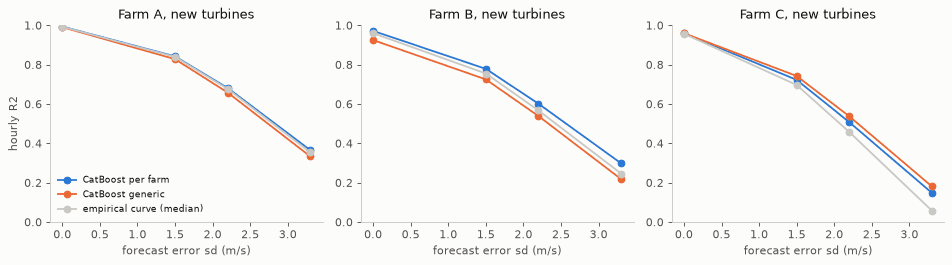

In [22]:
def unit_ar1(groups_hours, rng):
    """Unit-variance AR(1) noise on the continuous hourly grid of every time group."""
    out = []
    for g, d in groups_hours.groupby("group", sort=False):
        z = rng.standard_normal(len(d))
        e = np.empty(len(d))
        e[0] = z[0]
        a, b = NOISE_RHO, np.sqrt(1 - NOISE_RHO ** 2)
        for i in range(1, len(d)):
            e[i] = a * e[i - 1] + b * z[i]
        out.append(pd.DataFrame({"group": g, "hour": d["hour"].to_numpy(), "e": e}))
    return pd.concat(out, ignore_index=True)


GRID = pd.concat([pd.DataFrame({"group": g, "hour": pd.date_range(d["hour"].min(), d["hour"].max(), freq="h")})
                  for g, d in H[H["has_input"]].groupby("group")], ignore_index=True)


def sd_of(case, hours):
    if case != "ramp":
        return NOISE_SD[case]
    lead_days = (hours.values.astype("datetime64[h]").astype(np.int64) / 24.0) % 7 + 1 / 24
    return np.interp(lead_days, [1, 3, 7], [NOISE_SD["day 1"], NOISE_SD["day 3"], NOISE_SD["day 7"]])


def noisy_frames(case, rng):
    N = unit_ar1(GRID, rng)
    N["e"] = N["e"] * sd_of(case, N["hour"])
    own = H.drop(columns=["ws_d1", "ws_sd3"]).merge(N, on=["group", "hour"], how="left")
    own.index = H.index
    own["ws"] = np.maximum(own["ws"] + own["e"].fillna(0.0), 0.0)
    own = add_wind_features(own, "segment")

    def park_noise(G):
        return G[["group", "hour"]].merge(N, on=["group", "hour"], how="left")["e"].fillna(0.0).to_numpy()

    return own, park_frame(H, ws_noise=park_noise)


SENS_MODELS = ["CatBoost per farm", "CatBoost per farm, park wind", "CatBoost generic", "empirical curve (median)",
               "empirical curve per turbine (median)"]
sens = []
t_s = time.time()
for case in ["none"] + list(NOISE_SD) + ["ramp"]:
    draws = 1 if case == "none" else N_NOISE
    for k in range(draws):
        if case == "none":
            own, park = H, HP
        else:
            own, park = noisy_frames(case, np.random.default_rng(500 + k))
        for s in ["new", "future"]:
            models = [m for m in SENS_MODELS if (s, m) in FITTED]
            r = evaluate(s, predict_all(own, s, models), predict_all(park, s, models), models)
            r["case"], r["draw"] = case, k
            sens.append(r)
SENS = pd.concat(sens, ignore_index=True)
for c in ["R2", "WAPE 7d", "pair acc (own wind)", "pair acc (park wind)"]:
    SENS[c] = SENS[c].map(point)
SENS_T = SENS.groupby(["scheme", "farm", "model", "case"], sort=False)[["R2", "WAPE 7d", "pair acc (own wind)", "pair acc (park wind)"]].mean()
print(f"sensitivity in {time.time() - t_s:.0f} s")
for s in ["new", "future"]:
    print(f"=== {s.upper()}: R2 / WAPE 7d / pair accuracy (park wind) by forecast-error case")
    t = SENS_T.loc[s]
    display(pd.concat({c: t[c].unstack("case")[["none"] + list(NOISE_SD) + ["ramp"]] for c in ["R2", "WAPE 7d", "pair acc (park wind)"]},
                      axis=1).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
cases = ["none"] + list(NOISE_SD)
xs = [0] + list(NOISE_SD.values())
for ax, f in zip(axes, FARMS):
    for name, c in [("CatBoost per farm", BLUE), ("CatBoost generic", ORANGE), ("empirical curve (median)", MUTED)]:
        ax.plot(xs, [SENS_T.loc[("new", f, name, cs), "R2"] for cs in cases], c=c, marker="o", lw=1.6, label=name)
    ax.set_title(f"Farm {f}, new turbines")
    ax.set_xlabel("forecast error sd (m/s)")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("hourly R2")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
show(fig, "forecast_error_sensitivity")

## 10. Ablations

Future scheme (known turbines, where the turbine id can matter), per farm, the tree count fixed at the main model's.
Each row removes or adds one thing to the CatBoost per farm model.

In [23]:
main_iters = ITERS[(ITERS["scheme"] == "future") & (ITERS["model"] == "CatBoost per farm")].set_index("farms")["iterations"].to_dict()
VARIANTS = {
    "main": lambda f: FEATS["farm"][f],
    "no temperature": lambda f: [c for c in FEATS["farm"][f] if c != "temp"],
    "no direction": lambda f: [c for c in FEATS["farm"][f] if c not in DIR],
    "no turbine id": lambda f: [c for c in FEATS["farm"][f] if c != "turbine"],
    "no hour, no day of year": lambda f: [c for c in FEATS["farm"][f] if c not in TIME],
    "wind speed and turbine only": lambda f: ["ws", "turbine"],
    "plus gust factor": lambda f: FEATS["farm"][f] + ["gust"],
}
abl = {}
for vname, fn in VARIANTS.items():
    p_own, p_park = np.full(len(H), np.nan), np.full(len(H), np.nan)
    for f in FARMS:
        feats = fn(f)
        if vname == "no direction" and f == "C":
            continue
        tr = H[(H["farm"] == f) & H["has_target"] & ~H["future_test"]]
        m, _, _ = fit_catboost(tr, feats, int(main_iters[f]))
        te = H.index[(H["farm"] == f) & H["has_input"] & H["future_test"]]
        p_own[te] = m.predict(frame(H.loc[te], feats))
        p_park[te] = m.predict(frame(HP.loc[te], feats))
    abl[vname] = (p_own, p_park)
ABL = evaluate("future", pd.DataFrame({k: v[0] for k, v in abl.items()}), pd.DataFrame({k: v[1] for k, v in abl.items()}))
display(pd.DataFrame({"farm": ABL["farm"], "variant": ABL["model"], "R2 [CI]": ABL["R2"].map(fmt), "WAPE 7d [CI]": ABL["WAPE 7d"].map(fmt),
                      "pair acc own": ABL["pair acc (own wind)"].map(lambda v: f"{v[0]:.3f}"),
                      "pair acc park": ABL["pair acc (park wind)"].map(lambda v: f"{v[0]:.3f}")}).set_index(["farm", "variant"]))

                                               R2 [CI]          WAPE 7d [CI] pair acc own pair acc park
farm variant                                                                                           
A    main                         0.997 [0.996, 0.997]  0.013 [0.009, 0.018]        0.966         0.627
B    main                         0.981 [0.973, 0.987]  0.020 [0.016, 0.023]        0.800         0.500
C    main                         0.969 [0.963, 0.973]  0.040 [0.032, 0.048]        0.957         0.468
A    no temperature               0.997 [0.996, 0.997]  0.014 [0.009, 0.018]        0.966         0.661
B    no temperature               0.979 [0.972, 0.986]  0.023 [0.019, 0.027]        0.800         0.600
C    no temperature               0.969 [0.963, 0.973]  0.040 [0.032, 0.048]        0.915         0.505
A    no direction                 0.997 [0.996, 0.997]  0.013 [0.009, 0.018]        0.966         0.627
B    no direction                 0.979 [0.971, 0.986]  0.021 [0

**A park that is not in CARE.** The generic model is the only one that can run on a park outside CARE. Its honest test
is **leave one farm out**: train on two farms, predict the third. This is the closest CARE gets to a new park with a
different turbine type; the turbine-held-out folds above still have the other turbines of the same farm in training.

In [24]:
gen_iters = int(ITERS[(ITERS["scheme"] == "new") & (ITERS["model"] == "CatBoost generic")]["iterations"].median())
lofo = {"CatBoost generic, leave one farm out": np.full(len(H), np.nan), "empirical curve of the other two farms": np.full(len(H), np.nan)}
for f in FARMS:
    tr = H[(H["farm"] != f) & H["has_target"]]
    m, _, _ = fit_catboost(tr, FEATS["generic"], gen_iters)
    te = H.index[(H["farm"] == f) & H["has_input"]]
    lofo["CatBoost generic, leave one farm out"][te] = m.predict(frame(H.loc[te], FEATS["generic"]))
    lofo["empirical curve of the other two farms"][te] = eval_curve(fit_curve(tr["ws"].to_numpy(), tr["cf"].to_numpy(), "median"), H.loc[te, "ws"].to_numpy())
LOFO = evaluate("new", pd.DataFrame(lofo), pd.DataFrame(lofo))
display(pd.DataFrame({"farm": LOFO["farm"], "model": LOFO["model"], "R2 [CI]": LOFO["R2"].map(fmt), "bias": LOFO["bias"].map(lambda v: f"{v[0]:+.4f}"),
                      "WAPE 7d [CI]": LOFO["WAPE 7d"].map(fmt), "energy bias 7d": LOFO["energy bias 7d"].map(lambda v: f"{v[0]:+.3f}")}).set_index(["farm", "model"]))

                                                          R2 [CI]     bias          WAPE 7d [CI] energy bias 7d
farm model                                                                                                     
A    CatBoost generic, leave one farm out    0.981 [0.977, 0.985]  +0.0067  0.048 [0.034, 0.065]         +0.023
B    CatBoost generic, leave one farm out    0.888 [0.874, 0.903]  +0.0513  0.163 [0.144, 0.180]         +0.157
C    CatBoost generic, leave one farm out    0.913 [0.909, 0.916]  -0.0385  0.133 [0.128, 0.138]         -0.131
A    empirical curve of the other two farms  0.977 [0.971, 0.981]  +0.0112  0.055 [0.036, 0.078]         +0.040
B    empirical curve of the other two farms  0.885 [0.872, 0.900]  +0.0579  0.177 [0.156, 0.195]         +0.175
C    empirical curve of the other two farms  0.908 [0.904, 0.911]  -0.0314  0.118 [0.113, 0.124]         -0.109

## 11. Final models, feature contract, 7-day predictions

The final models are refitted on every hour with a clean target, with the tree count set to the median of the
new-turbine folds. Files go to `models/ml2/`; each must stay under the repo's 500 KB limit (about 1.1 KB per tree at
depth 6), so a model that would be larger keeps only its first trees; the table shows how much that changes its output.

In [25]:
FINAL = {
    "ml2_cf_farm_A.cbm": ("CatBoost per farm", ["A"], FEATS["farm"]["A"]),
    "ml2_cf_farm_B.cbm": ("CatBoost per farm", ["B"], FEATS["farm"]["B"]),
    "ml2_cf_farm_C.cbm": ("CatBoost per farm", ["C"], FEATS["farm"]["C"]),
    "ml2_cf_pooled.cbm": ("CatBoost pooled", FARMS, FEATS["pooled"]),
    "ml2_cf_generic.cbm": ("CatBoost generic", FARMS, FEATS["generic"]),
}
MAX_MODEL_BYTES = 480_000
final_rows, importance = [], {}
for fname, (model, farms, feats) in FINAL.items():
    it = ITERS[(ITERS["scheme"] == "new") & (ITERS["model"] == model) & (ITERS["farms"] == "".join(farms))]["iterations"]
    n_it = int(it.median())
    tr = H[H["farm"].isin(farms) & H["has_target"]]
    m, _, _ = fit_catboost(tr, feats, n_it)
    m.save_model(str(MODELS / fname))
    size = (MODELS / fname).stat().st_size
    kept, in_sample_change = n_it, 0.0
    if size >= MAX_MODEL_BYTES:
        # the pre-commit hook rejects files over 500 KB: drop the last trees (learning rate 0.05, so they add little)
        full_pred = m.predict(frame(tr, feats))
        kept = int(n_it * MAX_MODEL_BYTES / size * 0.98)
        m.shrink(ntree_end=kept)
        m.save_model(str(MODELS / fname))
        size = (MODELS / fname).stat().st_size
        in_sample_change = float(np.sqrt(np.mean((m.predict(frame(tr, feats)) - full_pred) ** 2)))
    assert size < 500_000, f"{fname} is {size} bytes, over the 500 KB pre-commit limit"
    importance[fname] = pd.Series(m.get_feature_importance(), index=feats).sort_values(ascending=False).round(1)
    final_rows.append({"file": fname, "model": model, "farms": "".join(farms), "trees (CV median)": n_it, "trees kept": kept,
                       "RMS change from dropped trees (cf)": round(in_sample_change, 5), "training hours": len(tr),
                       "size KB": round(size / 1024, 1), "features": len(feats)})
FINAL_T = pd.DataFrame(final_rows).set_index("file")
display(FINAL_T)
display(pd.concat(importance, axis=1).fillna(0).round(1))

                                model farms  trees (CV median)  trees kept  RMS change from dropped trees (cf)  training hours  size KB  features
file                                                                                                                                             
ml2_cf_farm_A.cbm   CatBoost per farm     A                 82          82                             0.00000          161620     96.9        11
ml2_cf_farm_B.cbm   CatBoost per farm     B                598         391                             0.00739          101851    481.2        11
ml2_cf_farm_C.cbm   CatBoost per farm     C                135         135                             0.00000          398428    156.4         9
ml2_cf_pooled.cbm     CatBoost pooled   ABC                361         335                             0.00114          661899    466.4        12
ml2_cf_generic.cbm   CatBoost generic   ABC                600         418                             0.00361          6618

         ml2_cf_farm_A.cbm  ml2_cf_farm_B.cbm  ml2_cf_farm_C.cbm  ml2_cf_pooled.cbm  ml2_cf_generic.cbm
ws                    98.4               87.0               94.9               87.9                92.6
temp                   0.7                1.6                0.8                0.7                 0.0
doy_cos                0.3                2.9                1.3                1.4                 3.7
turbine                0.2                1.1                2.1                1.7                 0.0
wd_sin                 0.1                1.2                0.0                2.1                 0.0
wd_cos                 0.1                1.7                0.0                2.2                 0.0
ws_sd3                 0.1                0.3                0.0                0.1                 0.3
doy_sin                0.0                2.7                0.6                0.8                 2.2
hod_cos                0.0                0.5                0.1

In [26]:
def headline(model, scheme, farm):
    r = RES[(RES["scheme"] == scheme) & (RES["model"] == model) & (RES["farm"] == farm)].iloc[0]
    return {"R2": round(point(r["R2"]), 3), "MAE": round(point(r["MAE"]), 4), "WAPE_7d": round(point(r["WAPE 7d"]), 3),
            "pair_accuracy_own_wind": round(point(r["pair acc (own wind)"]), 3),
            "pair_accuracy_park_wind": round(point(r["pair acc (park wind)"]), 3)}


FEATURE_SPEC = {
    "ws": {"source": "wind_speed_100m", "unit": "m/s", "transform": "identity",
           "care_training_proxy": "hourly mean nacelle wind speed (A wind_speed_3_avg, B wind_speed_61_avg, C wind_speed_236_avg)"},
    "ws_d1": {"source": "wind_speed_100m", "unit": "m/s", "transform": "ws(t) - ws(t - 1 h) within the park's hourly series; NaN for the first hour"},
    "ws_sd3": {"source": "wind_speed_100m", "unit": "m/s",
               "transform": "sample standard deviation (ddof=1) of ws over t-1 h, t, t+1 h, at least 2 values"},
    "temp": {"source": "temperature_2m", "unit": "degC",
             "transform": "temperature_2m minus the park's reference temperature (long-term median at the site)",
             "care_training_proxy": "ambient temperature minus the farm median (A sensor_0, B sensor_8, C sensor_7; exact zeros are missing)",
             "care_reference_degC": {k: round(float(v), 2) for k, v in TEMP_REF.items()}},
    "wd_sin": {"source": "wind_direction_100m", "unit": "deg", "transform": "sin(radians(direction))", "care_training_proxy": "A sensor_1, B sensor_4; C none"},
    "wd_cos": {"source": "wind_direction_100m", "unit": "deg", "transform": "cos(radians(direction))", "care_training_proxy": "A sensor_1, B sensor_4; C none"},
    "hod_sin": {"source": "forecast_time", "unit": "h", "transform": "sin(2 pi h / 24), h = local solar hour = (UTC hour + longitude / 15) mod 24"},
    "hod_cos": {"source": "forecast_time", "unit": "h", "transform": "cos(2 pi h / 24), h as above"},
    "doy_sin": {"source": "forecast_time", "unit": "day", "transform": "sin(2 pi doy / 365.25), doy = day of year of the UTC date (northern hemisphere)"},
    "doy_cos": {"source": "forecast_time", "unit": "day", "transform": "cos(2 pi doy / 365.25)"},
    "turbine": {"source": "CARE turbine id (string, e.g. 'C17')", "unit": None, "transform": "categorical",
                "note": "only meaningful for CARE turbines; database turbines are not CARE turbines"},
    "farm": {"source": "CARE farm id ('A', 'B', 'C')", "unit": None, "transform": "categorical"},
}
CONTRACT = {
    "name": "ML2 baseline: hourly available production per turbine",
    "created": "2026-11-08",
    "notebook": "notebooks/care_ml2_power_baseline.ipynb",
    "results": "notebooks/care_ml2_power_baseline.md",
    "target": {"name": "cf", "unit": "capacity factor (1.0 = rated power)",
               "definition": "hourly mean power of a healthy turbine in operation, without stops and curtailment (section 3)"},
    "output_to_energy": "MWh over the horizon = sum over forecast hours of clip(cf, 0, 1) * capacity_kw / 1000 (each row is one hour)",
    "expected_production": "expected = available x availability; availability is a per-turbine or per-park history factor, not part of the model",
    "source_table": "park_wind_forecast",
    "time_column": "forecast_time (timestamptz, start of the hour, UTC)",
    "row_unit": "one park and one hour; every turbine of the park gets the same weather inputs",
    "features": FEATURE_SPEC,
    "unused_forecast_columns": {
        "wind_speed_10m": "no counterpart at hub height in CARE",
        "wind_direction_10m": "no counterpart in CARE",
        "wind_gusts_10m": "only a loose counterpart (nacelle 10-minute max); tested as an ablation, not used",
        "relative_humidity_2m": "not measured in CARE",
        "dew_point_2m": "not measured in CARE",
        "surface_pressure": "not measured in CARE",
    },
    "models": {
        "ml2_cf_generic.cbm": {"features": FEATS["generic"], "trained_on": "farms A, B, C",
                               "use": "parks and turbines outside CARE (the database fleet)",
                               "leave_one_farm_out": {f: {"R2": round(point(r["R2"]), 3), "WAPE_7d": round(point(r["WAPE 7d"]), 3)}
                                                      for f, r in LOFO[LOFO["model"] == "CatBoost generic, leave one farm out"].set_index("farm").iterrows()}},
        "ml2_cf_pooled.cbm": {"features": FEATS["pooled"], "trained_on": "farms A, B, C", "use": "CARE turbines only"},
        **{f"ml2_cf_farm_{f}.cbm": {"features": FEATS["farm"][f], "trained_on": f"farm {f}", "use": f"CARE farm {f} turbines only",
                                    "new_turbines": headline("CatBoost per farm", "new", f), "future": headline("CatBoost per farm", "future", f)}
           for f in FARMS},
    },
    "postprocess": "clip cf to [0, 1] before converting to energy",
    "categorical_features": "pass turbine and farm as strings",
    "missing_values": "NaN is allowed (CatBoost default handling); wd_sin and wd_cos are NaN for farm C",
    "availability_care": {f: round(float(AVAIL.loc[AVAIL["farm"] == f, "availability"].median()), 3) for f in FARMS},
    "limits": [
        "trained on measured nacelle wind, served on forecast 100 m wind: CARE metrics are an upper bound (section 9)",
        "with one forecast row per park, turbines of the same park can only be ordered through what the model knows about each turbine",
    ],
}
(MODELS / "feature_contract.json").write_text(json.dumps(CONTRACT, indent=2) + "\n", encoding="utf-8")
print("written:", sorted(p.name for p in MODELS.iterdir()))

written: ['feature_contract.json', 'ml2_cf_farm_A.cbm', 'ml2_cf_farm_B.cbm', 'ml2_cf_farm_C.cbm', 'ml2_cf_generic.cbm', 'ml2_cf_pooled.cbm']


In [27]:
WEEK_COLS = {   # parquet column -> (model, inputs)
    "catboost_farm_own_cfh": ("CatBoost per farm", "own"),
    "catboost_farm_park_cfh": ("CatBoost per farm", "park"),
    "catboost_farm_parktrained_park_cfh": ("CatBoost per farm, park wind", "park"),
    "catboost_pooled_own_cfh": ("CatBoost pooled", "own"),
    "catboost_generic_own_cfh": ("CatBoost generic", "own"),
    "catboost_generic_park_cfh": ("CatBoost generic", "park"),
    "curve_theoretical_cfh": ("theoretical curve", "own"),
    "curve_empirical_median_cfh": ("empirical curve (median)", "own"),
    "climatology_turbine_hour_cfh": ("climatology (turbine x hour)", "own"),
}
AV_FARM = AVAIL.groupby("farm")["availability"].median()
weekly = []
for s in ["new", "future"]:
    m = EVAL_MASK[s]
    base = H.loc[m, ["farm", "turbine", "segment", "group", "week", "cf"]].copy()
    for col, (name, inputs) in WEEK_COLS.items():
        base[col] = (PRED if inputs == "own" else PRED_PARK)[s][name].to_numpy()[m]
    g = base.groupby(["farm", "turbine", "segment", "group", "week"])
    w = g["cf"].agg(["size", "sum"]).rename(columns={"size": "clean_hours", "sum": "energy_true_cfh"})
    for col in WEEK_COLS:
        w[col] = g[col].sum()
    w = w[w["clean_hours"] >= WEEK_MIN_HOURS].reset_index()
    w.insert(0, "scheme", "new_turbines" if s == "new" else "future")
    w["week_start"] = pd.to_datetime(w["week"] * 7, unit="D")
    av = AVAIL_TRAIN["availability"] if s == "future" else None
    w["availability"] = (w["turbine"].map(av) if av is not None else w["farm"].map(AV_FARM)).round(4)
    w["expected_catboost_farm_own_cfh"] = w["catboost_farm_own_cfh"] * w["availability"]
    weekly.append(w)
WEEKLY = pd.concat(weekly, ignore_index=True)
WEEKLY.to_parquet(OUT / "ml2_weekly_predictions.parquet", index=False)
print(f"ml2_weekly_predictions.parquet: {len(WEEKLY):,} rows; energy in capacity-factor hours (MWh = cfh x capacity_kw / 1000)")
display(WEEKLY.head(3).T)

RES_OUT = RES.copy()
for c in RES_OUT.columns:
    if RES_OUT[c].map(lambda v: isinstance(v, tuple)).any():
        RES_OUT[c + " lo"] = RES_OUT[c].map(lambda v: v[1])
        RES_OUT[c + " hi"] = RES_OUT[c].map(lambda v: v[2])
        RES_OUT[c] = RES_OUT[c].map(lambda v: v[0])
RES_OUT.to_csv(OUT / "results_main.csv", index=False)
SENS_T.reset_index().to_csv(OUT / "results_forecast_error.csv", index=False)
for name, t in [("results_ablation.csv", ABL), ("results_leave_one_farm_out.csv", LOFO)]:
    t.apply(lambda col: col.map(lambda v: v[0] if isinstance(v, tuple) else v)).to_csv(OUT / name, index=False)
PAIRED.to_csv(OUT / "results_vs_empirical_curve.csv", index=False)
EXPECTED.to_csv(OUT / "results_expected_vs_realized.csv")
CUT.to_csv(OUT / "cleaning_cut.csv")
BIAS.to_csv(OUT / "averaging_bias.csv")
ITERS.to_csv(OUT / "iterations.csv", index=False)

ml2_weekly_predictions.parquet: 4,339 rows; energy in capacity-factor hours (MWh = cfh x capacity_kw / 1000)


                                                      0                    1                    2
scheme                                     new_turbines         new_turbines         new_turbines
farm                                                  A                    A                    A
turbine                                             A00                  A00                  A00
segment                                           A00-0                A00-0                A00-0
group                                              Ag00                 Ag00                 Ag00
week                                               2505                 2506                 2507
clean_hours                                         168                  168                  168
energy_true_cfh                               51.992889            35.358597             24.16065
catboost_farm_own_cfh                         51.780446            34.610017            23.950464
catboost_farm_park_c

## 12. Summary

The numbers are printed below; the interpretation is in `notebooks/care_ml2_power_baseline.md`.

In [28]:
summary = RES[RES["model"].isin(["CatBoost per farm", "CatBoost per farm, park wind", "CatBoost pooled", "CatBoost generic",
                                 "empirical curve (median)", "empirical curve per turbine (median)", "theoretical curve",
                                 "climatology (turbine x hour)"])]
display(pd.DataFrame({"scheme": summary["scheme"], "farm": summary["farm"], "model": summary["model"],
                      "R2": summary["R2"].map(lambda v: round(v[0], 3)), "MAE": summary["MAE"].map(lambda v: round(v[0], 4)),
                      "WAPE 7d": summary["WAPE 7d"].map(lambda v: round(v[0], 3)),
                      "pair acc own": summary["pair acc (own wind)"].map(lambda v: round(v[0], 3)),
                      "pair acc park": summary["pair acc (park wind)"].map(lambda v: round(v[0], 3))}).set_index(["scheme", "farm", "model"]))
print(f"total run time {(time.time() - T0) / 60:.1f} min")

                                                     R2     MAE  WAPE 7d  pair acc own  pair acc park
scheme farm model                                                                                    
new    A    CatBoost per farm                     0.994  0.0156    0.032         0.800          0.452
            CatBoost per farm, park wind          0.990  0.0224    0.044         0.765          0.299
            CatBoost pooled                       0.992  0.0183    0.043         0.784          0.323
            CatBoost generic                      0.990  0.0191    0.036         0.804          0.361
            theoretical curve                     0.645  0.1349    0.465         0.843          0.500
            empirical curve (median)              0.993  0.0154    0.039         0.804          0.287
            climatology (turbine x hour)          0.029  0.2713    0.454         0.246          0.246
       B    CatBoost per farm                     0.972  0.0306    0.036         0

total run time 14.1 min
